# Sesgo de género en biografías · Parte 2: confirmación final y métrica

Este cuaderno es la **segunda parte** del estudio. La primera (`sesgo_genero_parte_1.ipynb`) contiene la fase
exploratoria: datos, filtro de plantillas, descubrimiento N05 y las rondas 1 a 3 con las variables originales. A partir
de sus resultados se revisaron las variables; aquí se **confirman con biografías nuevas** y se mide el sesgo.

**Criterio.** No se mide cómo son las mujeres y los hombres, sino **cómo se elige contarlos**. Un hecho de la persona
no es sesgo; lo es lo que se añade, se destaca o se omite. Un tema solo cuenta como sesgo si **no es relevante para su
trabajo**, juzgado desde el propio texto (vale para cualquier profesión).

**Qué hace**
1. Saca una **muestra nueva**: 40 biografías por profesión y género, no usadas en ninguna fase anterior.
2. La **anota** con las variables revisadas: forma, **encuadre** (el tema se añade como etiqueta) y **puesta en valor**
   (forma parte de su trabajo y se valora o no).
3. **Confirmatorio**: dirección fijada de antemano, unilateral, Benjamini-Hochberg al 0,05.
4. Descriptivas, análisis por profesión, **7 dimensiones** y **gráficos radiales**.
5. **Métrica de sesgo de 0 a 1** ajustada a cada profesión (70 % presencia de sesgos, 30 % omisión agéntica), con su
   explicación.

**Requisitos:** va en la **misma carpeta** que la parte 1 y usa su `cache/` y `resultados/`. No hace falta volver a
ejecutar la parte 1. La anotación (≈ 6.700 llamadas) se guarda cada 40 biografías y se retoma si se corta.


### Dos muestras nuevas: confirmación y ampliación
1. **Confirmación** (`FASE = "confirmacion"`, ya hecha): 2.240 biografías nuevas, criterio **FDR 0,05** fijado antes de
   anotarlas. Se confirmaron 13 de 38 hipótesis; varias agénticas se quedaron cerca (p corregida ≈ 0,05).
2. **Ampliación** (`FASE = "ampliacion"`): **otras** 2.240 biografías que no se han usado en ninguna fase. El criterio
   se fija **ahora, antes de anotarlas** (27/10/2026): Benjamini-Hochberg con **FDR 0,10**, unilateral, las mismas
   hipótesis. `excepcionalidad` se prueba ya en el lado agéntico (más en hombres), porque esta muestra no se ha visto.
   **La métrica final usa las variables confirmadas en la ampliación.**

Cada fase guarda sus archivos con su sufijo (`_confirmacion` o `_ampliacion`), así que no se pisan.


## 0. Instalación
Solo instala lo que falte.

In [1]:
import importlib.util, subprocess, sys

PAQUETES = {"pandas": "pandas", "pyarrow": "pyarrow", "spacy": "spacy", "statsmodels": "statsmodels",
            "scipy": "scipy", "sklearn": "scikit-learn", "matplotlib": "matplotlib",
            "dotenv": "python-dotenv", "openai": "openai"}
faltan = [pip for modulo, pip in PAQUETES.items() if importlib.util.find_spec(modulo) is None]
if faltan:
    print("Instalando:", ", ".join(faltan))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltan], check=True)
if importlib.util.find_spec("en_core_web_sm") is None:
    subprocess.run([sys.executable, "-m", "spacy", "download", "en_core_web_sm", "-q"], check=True)
print("Paquetes listos.")

Paquetes listos.


## 1. Configuración
Todo lo que podrías querer cambiar está aquí.

In [2]:
import os, re, json, time, warnings, unicodedata
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

CACHE, RESULTADOS = Path("cache"), Path("resultados")
RESULTADOS.mkdir(exist_ok=True)
ENV = "/workspace/equipo10/.env"
MODELO = "Qwen3.5-397B-A17B"
HILOS = 8                      # llamadas simultáneas (bájalo a 4 si da muchos errores de conexión)

# --- Fase del análisis ---
#   "confirmacion": primera muestra nueva (ya anotada). Criterio fijado antes de anotarla: FDR 0,05.
#   "ampliacion":   segunda muestra nueva, sin repetir ninguna biografía. Criterio fijado el 27/10/2026,
#                   ANTES de anotarla: FDR 0,10. Es la que decide qué variables entran en la métrica final.
FASE = "ampliacion"
FASES = {"confirmacion": {"semilla": 10, "n": 40, "alfa": 0.05},
         "ampliacion":   {"semilla": 11, "n": 40, "alfa": 0.10}}   # n = por profesión y género
SUF = FASE                                    # sufijo de los archivos de resultados
ETIQUETA_FASE = {"confirmacion": "muestra de confirmación", "ampliacion": "muestra de ampliación"}[FASE]
MUESTRA_NUEVA = {**FASES[FASE], "anotaciones": f"anotaciones_{SUF}.csv"}

# --- Contrastes ---
ALFA_CONFIRMATORIO = FASES[FASE]["alfa"]
CORRECCION_CONFIRMATORIA = "fdr_bh"   # Benjamini-Hochberg
ALFA_EXPLORATORIO = 0.10

# --- Métrica de sesgo (0 = ningún sesgo, 1 = todos) ---
PESO_PRESENCIA = 0.70    # parte 1: rasgos de sesgo presentes (marcado, vida personal, comunal, agencia diluida)
PESO_OMISION = 0.30      # parte 2: rasgos agénticos que faltan
MIN_TASA_HOMBRES = 10    # % mínimo en hombres de la profesión para considerar que algo "suele aparecer"
K_SUAVIZADO = 40         # cuánto se acercan las tasas de cada profesión a las generales (más alto = más)
N_PLIEGUES = 5           # validación cruzada al puntuar las biografías de la muestra (evita que se puntúen a sí mismas)
VARIABLES_METRICA = "confirmadas"   # "confirmadas" (lo correcto) o "hipotesis" (todas, solo para explorar)
EXCLUIR_N05_EN_ANALISIS = False     # True: repite el análisis sin las biografías tomadas de N05

PROFESIONES = ["accountant", "architect", "attorney", "chiropractor", "comedian", "composer",
               "dentist", "dietitian", "dj", "filmmaker", "interior_designer", "journalist",
               "model", "nurse", "painter", "paralegal", "pastor", "personal_trainer",
               "photographer", "physician", "poet", "professor", "psychologist", "rapper",
               "software_engineer", "surgeon", "teacher", "yoga_teacher"]
NOMBRES = {
    "accountant": "contable", "architect": "arquitecto/a", "attorney": "abogado/a",
    "chiropractor": "quiropráctico/a", "comedian": "cómico/a", "composer": "compositor/a",
    "dentist": "dentista", "dietitian": "dietista", "dj": "DJ", "filmmaker": "cineasta",
    "interior_designer": "interiorista", "journalist": "periodista", "model": "modelo",
    "nurse": "enfermero/a", "painter": "pintor/a", "paralegal": "asistente legal", "pastor": "pastor/a",
    "personal_trainer": "entrenador/a personal", "photographer": "fotógrafo/a", "physician": "médico/a",
    "poet": "poeta", "professor": "profesor/a universitario/a", "psychologist": "psicólogo/a",
    "rapper": "rapero/a", "software_engineer": "ingeniero/a de software", "surgeon": "cirujano/a",
    "teacher": "docente (escuela)", "yoga_teacher": "profesor/a de yoga",
}
print("Configuración cargada.")

Configuración cargada.


## 2. Datos y muestra de confirmación
- Se cargan las biografías **sin plantilla** que ya preparó el cuaderno del estudio (`cache/df_limpio_*.parquet`).
- Nunca se reutilizan las biografías de las rondas 1, 2 y 3.
- Tampoco las del descubrimiento (N05), salvo en las profesiones y géneros donde no quedan bastantes: N05 usó casi
  todas las biografías del género minoritario en algunas profesiones. Esas se marcan en la columna `de_n05` y se
  pueden excluir del análisis con `EXCLUIR_N05_EN_ANALISIS = True` (comprobación de robustez).
- Se sortean 40 biografías por profesión y género (misma cantidad de mujeres y hombres) y se guarda la muestra.

In [3]:
archivos = sorted(CACHE.glob("df_limpio_*.parquet"))
if not archivos:
    raise FileNotFoundError("No encuentro cache/df_limpio_*.parquet: ejecuta antes el cuaderno del estudio (pasos 2 y 3).")
df_limpio = pd.read_parquet(archivos[-1])
print("Biografías sin plantilla:", len(df_limpio), df_limpio["genero"].value_counts().to_dict())

EN_RONDAS = set()
for f in CACHE.glob("muestra_ronda[123].parquet"):
    EN_RONDAS |= set(pd.read_parquet(f, columns=["texto"])["texto"])
EN_N05 = set()
for f in CACHE.glob("n05_textos_v*.parquet"):
    EN_N05 |= set(pd.read_parquet(f, columns=["texto"])["texto"])
if FASE == "ampliacion":   # tampoco se repiten las de la muestra de confirmación
    for f in [CACHE / "muestra_confirmacion.parquet", CACHE / "muestra_ronda4.parquet"]:
        if f.exists():
            EN_RONDAS |= set(pd.read_parquet(f, columns=["texto"])["texto"])
print("Biografías ya usadas (rondas anteriores):", len(EN_RONDAS), "| descubrimiento N05:", len(EN_N05))

ARCH_MUESTRA = CACHE / f"muestra_{SUF}.parquet"
if ARCH_MUESTRA.exists():
    muestra_rev = pd.read_parquet(ARCH_MUESTRA)
    print("Muestra cargada desde caché:", ARCH_MUESTRA)
else:
    # Las de las rondas 1 a 3 nunca se reutilizan. Las de N05 solo se usan si en una profesión y género no quedan
    # bastantes (en profesiones con pocas mujeres o pocos hombres, N05 usó casi todas). Se marcan en `de_n05`.
    libres = df_limpio[~df_limpio["texto"].isin(EN_RONDAS)].copy()
    libres["de_n05"] = libres["texto"].isin(EN_N05)
    partes, faltas = [], []
    for (prof, gen), g in libres.groupby(["profesion", "genero"]):
        nuevas, n05 = g[~g["de_n05"]], g[g["de_n05"]]
        toma = nuevas.sample(min(MUESTRA_NUEVA["n"], len(nuevas)), random_state=MUESTRA_NUEVA["semilla"])
        falta = MUESTRA_NUEVA["n"] - len(toma)
        if falta > 0:
            extra = n05.sample(min(falta, len(n05)), random_state=MUESTRA_NUEVA["semilla"])
            toma = pd.concat([toma, extra])
            faltas.append({"profesion": prof, "genero": gen, "nuevas": len(nuevas), "de_n05": len(extra),
                           "total": len(toma)})
        partes.append(toma)
    muestra_rev = pd.concat(partes).reset_index(drop=True)
    muestra_rev.insert(0, "idx", range(len(muestra_rev)))
    muestra_rev.to_parquet(ARCH_MUESTRA, index=False)
    if faltas:
        print("Profesiones y géneros sin bastantes biografías nuevas (se completan con textos de N05):")
        display(pd.DataFrame(faltas))
if "de_n05" not in muestra_rev.columns:
    muestra_rev["de_n05"] = muestra_rev["texto"].isin(EN_N05)
print(f"Muestra ({ETIQUETA_FASE}):", len(muestra_rev), "biografías", muestra_rev["genero"].value_counts().to_dict(),
      "| de rondas anteriores:", muestra_rev["texto"].isin(EN_RONDAS).sum(),
      "| de N05:", int(muestra_rev["de_n05"].sum()))

# % de mujeres de cada profesión en el dataset (para los títulos y el tipo de profesión)
COMP = df_limpio.groupby("profesion")["genero"].apply(lambda g: (g == "woman").mean() * 100)
TIPO_PROF = COMP.map(lambda p: "menos del 35 % de mujeres" if p < 35 else
                     ("más del 65 % de mujeres" if p > 65 else "entre 35 y 65 % de mujeres"))
ORDEN_TIPOS = ["menos del 35 % de mujeres", "entre 35 y 65 % de mujeres", "más del 65 % de mujeres"]

Biografías sin plantilla: 356335 {'man': 192408, 'woman': 163927}
Biografías ya usadas (rondas anteriores): 6697 | descubrimiento N05: 57717
Profesiones y géneros sin bastantes biografías nuevas (se completan con textos de N05):


,profesion,genero,nuevas,de_n05,total
0,chiropractor,woman,0,40,40
1,comedian,woman,0,40,40
2,composer,woman,0,40,40
3,dietitian,man,0,40,40
4,dj,woman,0,40,40
5,interior_designer,man,0,40,40
6,model,man,0,40,40
7,nurse,man,0,40,40
8,paralegal,man,0,40,40
9,pastor,woman,0,40,40


Muestra (muestra de ampliación): 2222 biografías {'man': 1120, 'woman': 1102} | de rondas anteriores: 0 | de N05: 582


### Resultados de la parte 1 (rondas 1 a 3, variables originales)
Solo se muestran: están guardados en `resultados/`. De aquí salió la revisión de variables.
- **Ronda 1** (exploratoria) → hipótesis de la ronda 2.
- **Ronda 2** (confirmatoria) → 2 confirmadas (marcado de género, nombre de pila) y varias pistas.
- **Ronda 3** (confirmatoria, 26 hipótesis) → 21 confirmadas.

In [4]:
for nombre in ["confirmatorio_ronda2.csv", "confirmatorio_ronda3.csv"] + (["confirmatorio_confirmacion.csv"] if FASE == "ampliacion" else []):
    archivo = RESULTADOS / nombre
    if archivo.exists():
        t = pd.read_csv(archivo)
        print(f"\n=== {nombre} · confirmadas: {int(t['confirmada'].sum())} de {len(t)} ===")
        display(t[["variable", "direccion_esperada", "hombres", "mujeres", "efecto_mujer", "p_corregida", "confirmada"]])
    else:
        print("No encuentro", archivo)


=== confirmatorio_ronda2.csv · confirmadas: 2 de 6 ===


,variable,direccion_esperada,hombres,mujeres,efecto_mujer,p_corregida,confirmada
0,marcado_genero,más en mujeres,1.19,5.03,5.28,0.000977,True
1,forma_nombrar = nombre_pila,más en mujeres,47.88,58.09,1.63,0.014865,True
2,menciona_experiencia,menos en mujeres,25.30,24.37,0.94,0.555486,False
3,menciona_estado_civil,más en mujeres,2.37,2.51,1.00,0.619679,False
4,posicion_mencion_familiar = primera_mitad,más en mujeres,69.23,54.55,0.31,0.993785,False
5,presentada_por_otra_persona,más en mujeres,0.00,0.19,NaN,NaN,False



=== confirmatorio_ronda3.csv · confirmadas: 21 de 26 ===


,variable,direccion_esperada,hombres,mujeres,efecto_mujer,p_corregida,confirmada
0,marcado_genero,más en mujeres,1.08,6.17,6.52,1.549296e-07,True
1,forma_nombrar = nombre_pila,más en mujeres,48.12,55.96,1.49,3.573976e-03,True
2,marca_genero_persona,más en mujeres,0.39,3.13,9.09,7.878567e-05,True
3,espacio_un_genero,más en mujeres,0.89,4.08,4.79,7.306438e-05,True
4,n_adj_calidez,más en mujeres,0.10,0.13,1.37,2.194317e-02,True
5,logros_en_pasiva = si,más en mujeres,31.93,36.57,1.16,2.111258e-01,False
6,tono = neutro,más en mujeres,36.61,35.20,0.93,8.223755e-01,False
7,n_adj_agencia,menos en mujeres,0.49,0.35,0.73,3.950444e-04,True
8,n_logros,menos en mujeres,0.75,0.67,0.84,1.324987e-02,True
9,orientacion_cuidado,más en mujeres,16.34,23.43,1.77,2.500942e-05,True



=== confirmatorio_confirmacion.csv · confirmadas: 13 de 38 ===


,variable,direccion_esperada,hombres,mujeres,efecto_mujer,p_corregida,confirmada
0,marcado_genero,más en mujeres,0.69,4.21,6.83,0.000040,True
1,marca_genero_persona,más en mujeres,0.69,3.35,5.30,0.000372,True
2,excepcionalidad,más en mujeres,5.45,3.35,0.60,0.988942,False
3,forma_nombrar,más en mujeres,50.52,57.07,1.50,0.006329,True
4,menciona_pareja,más en mujeres,4.06,4.97,1.25,0.264518,False
5,menciona_hijos,más en mujeres,2.97,4.88,1.73,0.033831,True
6,menciona_estado_civil,más en mujeres,2.57,2.58,1.00,0.613261,False
7,menciona_padres_origen,más en mujeres,7.43,8.89,1.23,0.191475,False
8,presentada_por_otra_persona,más en mujeres,0.00,0.38,NaN,NaN,False
9,menciona_aficiones,más en mujeres,9.01,12.24,1.45,0.020789,True


## 3. Enmascarado
Como en el estudio: pronombres → `[X]`, nombres de persona → `[NAME]` (spaCy).

In [5]:
PRONOMBRES = r"\b(she|he|her|hers|him|his|herself|himself|mrs|mr|ms|miss|mister|madam)\b"
_nlp = None

def get_nlp():
    global _nlp
    if _nlp is None:
        import spacy
        _nlp = spacy.load("en_core_web_sm", disable=["tagger", "parser", "attribute_ruler", "lemmatizer"])
    return _nlp

def enmascarar_lote(textos):
    salida = []
    for doc in get_nlp().pipe(textos, batch_size=500):
        t = doc.text
        for ent in reversed(doc.ents):
            if ent.label_ == "PERSON":
                t = t[:ent.start_char] + "[NAME]" + t[ent.end_char:]
        salida.append(re.sub(PRONOMBRES, "[X]", t, flags=re.IGNORECASE))
    return salida

if "texto_enmascarado" not in muestra_rev.columns:
    print("Enmascarando la muestra (tarda unos minutos)...")
    muestra_rev["texto_enmascarado"] = enmascarar_lote(muestra_rev["texto"].tolist())
    muestra_rev.to_parquet(ARCH_MUESTRA, index=False)
print("Textos enmascarados listos.")

Enmascarando la muestra (tarda unos minutos)...
Textos enmascarados listos.


## 4. Conexión con el modelo
La dirección y el token se leen del archivo `.env`.

In [6]:
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv(ENV, override=True)
############
ai_endpoint_url = os.getenv("OVH_AI_ENDPOINTS_URL")
ai_endpoint_token = os.getenv("OVH_AI_ENDPOINTS_ACCESS_TOKEN")
if not ai_endpoint_url or not ai_endpoint_token:
    raise RuntimeError(f"No se han podido leer la dirección o el token del archivo {ENV}.")
client = OpenAI(base_url=ai_endpoint_url, api_key=ai_endpoint_token)
##############
def preguntar(prompt):
    for intento in range(3):
        try:
            r = client.chat.completions.create(model=MODELO, messages=[{"role": "user", "content": prompt}],
                                               temperature=0, reasoning_effort="none")
            contenido = r.choices[0].message.content
            ini, fin = contenido.find("{"), contenido.rfind("}")
            return json.loads(contenido[ini:fin + 1]) if ini != -1 else {}
        except json.JSONDecodeError:
            return {}
        except Exception as e:
            print("Error de conexión, reintentando:", type(e).__name__)
            time.sleep(3 * (intento + 1))
    return {}

def hay_conexion():
    return preguntar('Return the JSON {"ok": true}').get("ok") is True

print("Conexión con el modelo:", "OK" if hay_conexion() else "FALLA (no lances la anotación)")

Conexión con el modelo: OK


## 5. Variables revisadas
Tres llamadas por biografía:
1. **Forma** (texto enmascarado): variables de sí/no y recuentos. `marcado_genero` lleva la pregunta corregida
   (ya no cuenta los cargos con género como *actress* o *chairman*).
2. **Contexto** (texto enmascarado): variables de **encuadre** (`no_aparece / hecho / encuadre`), de **puesta en
   valor** (`no_aplica / aplica_no_destaca / aplica_destaca`), aspecto físico y las 4 variables descubiertas que se
   mantienen.
3. **Nombre** (texto original, porque necesita ver los nombres): forma de nombrar y uso del título.

Eliminadas: `militar_riesgo`, `deporte_fisico`, `aficiones_aire_libre_mecanica`, `narrativa_expresion`,
`identidad_lgtbi`, `obstaculos_genero`, `menciona_edad`, `n_frases_vida_personal`. `menciona_apariencia` y
`usa_titulo` se sustituyen por sus versiones `_ctx`; los temas de N05 que cambian pasan a `_ctx`.

In [7]:
VARIABLES_FORMA = {
    # --- Control ---
    "tipo_texto": (["biografia", "no_biografia"],
        "Is this text a description of a person's work, career, education, skills or life? Answer 'biografia' if it is, even if it starts mid-story, is short, lists services or specialties, or contains some extra details. Answer 'no_biografia' ONLY if it gives almost no information about the person (just contact details, navigation text, an advertisement or an unrelated text)."),
    # --- Vida personal ---
    "menciona_pareja": ("bool",
        "Does the text mention a spouse or romantic partner (husband, wife, partner, fiancé/fiancée, boyfriend, girlfriend, significant other)?"),
    "papel_pareja": (["coprotagonista", "apoyo", "solo_mencion", "no_aparece"],
        "If a spouse or partner is mentioned, what role do they play? 'coprotagonista' if the partner shares the person's professional work or achievements ('she and her husband founded', 'works in conjunction with her husband'); 'apoyo' if the partner is described as supporting the person ('supported in ministry by his wife'); 'solo_mencion' if the partner is only mentioned as a personal detail ('lives with his wife and two children'); 'no_aparece' if no partner is mentioned."),
    "menciona_hijos": ("bool",
        "Does the text mention children or grandchildren (sons, daughters, kids, stepchildren, 'mother of', 'father of', 'mom', 'dad', 'parent of')?"),
    "menciona_estado_civil": ("bool",
        "Does the text mention marital status (married, single, divorced, widowed, engaged)?"),
    "menciona_padres_origen": ("bool",
        "Does the text mention the person's parents, siblings or family background, or where they grew up or were raised (hometown, childhood, family origins)?"),
    "presentada_por_otra_persona": ("bool",
        "Is the person introduced or defined mainly through their relationship with a partner or family member, so that this relationship is presented as a central part of who they are ('wife of', 'former wife of actor…', 'daughter of famous…', 'married to NBA player…')? Do NOT count: describing who they work for or assist as part of their job (e.g. a paralegal assisting an attorney), being discovered or helped by someone, simply mentioning family background, or simply saying they are married."),
    "menciona_aficiones": ("bool",
        "Does the text mention hobbies, free time or personal interests outside work (sports, travel, cooking, reading, music, pets, 'in their spare time', 'when not at work')?"),
    "posicion_mencion_familiar": (["primera_mitad", "segunda_mitad", "no_aparece"],
        "Where does the FIRST mention of family (partner, children, parents, marital status) appear in the text?"),
    # --- Logros, formación y trayectoria ---
    "n_logros": ("int",
        "How many distinct achievements or recognitions are mentioned (awards, prizes, honours, rankings, nominations, grants, being selected or named for something, notable publications, exhibitions, record sales, notable clients)? Do not count degrees or certifications."),
    "n_credenciales": ("int",
        "How many distinct educational or professional credentials are mentioned (degrees, diplomas, certifications, licenses, board certifications, fellowships, residencies, training programs)?"),
    "menciona_experiencia": ("bool",
        "Does the text mention length of experience or career ('over 10 years of experience', 'two decades', 'since 1995', 'veteran', 'seasoned', 'long career')?"),
    "menciona_liderazgo": ("bool",
        "Is the person described in a leadership, management or ownership role (founder, co-founder, owner, director, head, chief, CEO, president, chair, manager, partner in a firm, principal, leads or supervises a team or department)?"),
    "atribuye_logros_a_otros": (["si", "no", "sin_logros"],
        "Are any of the person's achievements credited to other people or to circumstances (a mentor, spouse, family, team, collaborators, luck, being discovered by someone, support from others)? Answer 'sin_logros' if no achievements are mentioned."),
    "logros_en_pasiva": (["si", "no", "sin_logros"],
        "Is any achievement described in the passive voice ('was awarded', 'was named', 'was selected', 'was recognized', 'was honored')? Answer 'sin_logros' if no achievements are mentioned."),
    # --- Orientación profesional ---
    "orientacion_cuidado": ("bool",
        "Does the text emphasize helping, caring for or serving others (patients, clients, students, families, community), e.g. 'dedicated to helping', 'committed to patient care', 'passion for serving'?"),
    "menciona_impacto": ("bool",
        "Does the text emphasize the person's influence, impact, reach or authority (shaped the field, widely cited, recognized authority, transformed, led change, international reputation)?"),
    "menciona_innovacion": ("bool",
        "Does the text describe the person as creating, inventing or innovating (developed a new method, patents, founded, pioneered a technique, built a product)?"),
    "menciona_docencia_mentoria": ("bool",
        "Does the text mention teaching, mentoring, training or supervising others' learning?"),
    "menciona_voluntariado": ("bool",
        "Does the text mention volunteering, charity, non-profit work, community service or pro bono work?"),
    "menciona_especializacion": ("bool",
        "Does the text mention a specific area of specialization or technical expertise (specializes in, focuses on, expert in a specific technique or area)?"),
    # --- Excepcionalidad y marcado de género (marcado_genero, pregunta corregida) ---
    "excepcionalidad": ("bool",
        "Is the person described as exceptional or a pioneer within a group or field: first, only, one of the few, pioneer, pioneering, trailblazer, groundbreaking figure, breaking barriers, rare, unique among peers, leading the way? It must describe the person, not a product or place (e.g. 'the first clinic in town' does not count)."),
    "marcado_genero": ("bool",
        "Does the text explicitly mark the person's gender in relation to their profession or role: 'female engineer', 'woman surgeon', 'male nurse', 'lady doctor', 'women in tech', 'first woman to…'? Do NOT count gendered job titles on their own (actress, actor, chairwoman, chairman, spokeswoman, spokesman, businesswoman, waitress): they are a separate question."),
    "marca_genero_persona": ("bool",
        "Does the text explicitly point out the person's own gender as relevant to who they are or what they do ('as a woman', 'as a Black Muslim woman', 'female engineer', 'male nurse', 'Best Female Comic', 'first woman to…', 'everywoman', 'ChiroMom')? Do NOT count gendered job titles alone (actress, spokeswoman) or mentions of women-only or men-only groups."),
    "titulo_con_genero": ("bool",
        "Does the text use a gendered job title or role noun for the person (actress, actor, chairwoman, chairman, spokeswoman, spokesman, businesswoman, businessman, songstress, hostess, waitress)?"),
    "espacio_un_genero": ("bool",
        "Does the text mention groups, events, awards, shows or organizations restricted to or focused on one gender ('all-female showcase', 'women's network', 'Women in Law', 'men's ministry', 'ladies' night')?"),
    # --- Lenguaje ---
    "n_adj_agencia": ("int",
        "How many words describe agency or competence (confident, ambitious, driven, independent, decisive, assertive, determined, accomplished, successful, influential, expert, outstanding, leading)?"),
    "n_adj_calidez": ("int",
        "How many words describe warmth or communal traits (warm, caring, compassionate, kind, supportive, nurturing, helpful, friendly, patient, gentle, empathetic, approachable, loving)?"),
    "n_palabras_capacidad": ("int",
        "How many words attribute success to ability or talent (talented, gifted, brilliant, intelligent, skilled, natural, exceptional, genius, innovative, creative)?"),
    "n_palabras_esfuerzo": ("int",
        "How many words attribute success to effort (hardworking, dedicated, diligent, committed, tireless, conscientious, meticulous, persistent, devoted, works hard)?"),
    "n_expresiones_duda": ("int",
        "How many expressions cast doubt or give faint praise (tries to, hopes to, aspiring, may, seems, somewhat, fairly, adequate, although, despite, still learning)?"),
    "n_terminos_emocion": ("int",
        "How many words refer to emotions or temperament (passionate, loves, enjoys, excited, proud, happy, enthusiastic, sensitive, emotional, cheerful, calm, energetic)?"),
    "n_verbos_rol_activo": ("int",
        "How many verbs present the person as the main agent who leads, decides or creates (leads, directs, manages, founded, created, developed, designed, built, launched, oversees, heads)?"),
    "n_verbos_rol_apoyo": ("int",
        "How many verbs present the person in a supporting or assisting role (assists, supports, helps, aids, contributes to, works with, works under, collaborates on, serves)?"),
    "tono": (["positivo", "neutro", "negativo"],
        "What is the overall tone of the text?"),
}

VARIABLES_CONTEXTO = {
    # --- Encuadre: el sesgo es 'encuadre' (se añade o se etiqueta sin un hecho concreto) ---
    "menciona_apariencia_ctx": (["no_aparece", "relevante", "no_relevante"],
        "Does the text comment on the person's own physical appearance (looks, beauty, attractiveness, body, height, weight, hair, clothing, style)? Answer 'no_aparece' if not. Answer 'relevante' if the person's work is directly about their image or appearance (model, actor or actress, fitness or beauty influencer, stylist, TV presenter) and the comment relates to that work. Answer 'no_relevante' if their appearance is mentioned although it has nothing to do with their work. Judge only from the text itself, whatever the profession."),
    "bienestar_sanacion_ctx": (["no_aparece", "hecho", "encuadre"],
        "Does the text mention wellness, healing or holistic well-being (healing, wellness, holistic, mindfulness, self-care, emotional well-being, nurturing)? Answer 'no_aparece' if it is not mentioned. Answer 'hecho' if it describes something concrete the person does: it is their field, specialty, clients, products or services, or a specific activity, organization or project. Answer 'encuadre' if it appears as a label, adjective or way of presenting the person or their work, without a concrete fact behind it or without being needed to describe what they do (for example: a lawyer 'who brings a holistic, healing touch to every case', an accountant who 'radiates calm and well-being'). Judge only from the text itself, whatever the profession. Do not count comments on the person's own appearance or own family."),
    "infancia_familias_ctx": (["no_aparece", "hecho", "encuadre"],
        "Does the text mention children, babies, parents or families as people the person works with or for (pediatric, early childhood, maternity, parenting, family services)? Answer 'no_aparece' if it is not mentioned. Answer 'hecho' if it describes something concrete the person does: it is their field, specialty, clients, products or services, or a specific activity, organization or project. Answer 'encuadre' if it appears as a label, adjective or way of presenting the person or their work, without a concrete fact behind it or without being needed to describe what they do (for example: a general dentist described as 'great with kids', a lawyer who 'also enjoys helping families', a 'family-friendly' practice). Judge only from the text itself, whatever the profession. Do not count comments on the person's own appearance or own family."),
    "estetica_belleza_ctx": (["no_aparece", "hecho", "encuadre"],
        "Does the text mention beauty, fashion, style, makeup, hair, flowers or decoration as a topic? Answer 'no_aparece' if it is not mentioned. Answer 'hecho' if it describes something concrete the person does: it is their field, specialty, clients, products or services, or a specific activity, organization or project. Answer 'encuadre' if it appears as a label, adjective or way of presenting the person or their work, without a concrete fact behind it or without being needed to describe what they do (for example: a lawyer 'with a passion for fashion', an engineer 'known for her sense of style', a dentist who 'loves makeup and interior decor'). Judge only from the text itself, whatever the profession. Do not count comments on the person's own appearance or own family."),
    "activismo_justicia_social_ctx": (["no_aparece", "hecho", "encuadre"],
        "Does the text mention activism or social causes (feminism, women's rights, gender equality, empowerment, civil or human rights, giving a voice to marginalized people)? Answer 'no_aparece' if not. Answer 'hecho' if it describes something concrete the person does: their job is in this field, or they founded, lead, work for or volunteer at a specific organization, campaign, case or project. Answer 'encuadre' if these words are used to label or frame the person or their ordinary work without a concrete activity behind them (for example: 'empowering women through yoga', 'a feminist voice in comedy', 'inspiring girls to dream big')."),
    # --- Puesta en valor: el sesgo es 'aplica_no_destaca' (forma parte de su trabajo y no se valora) ---
    "ciencia_cuantitativa_ctx": (["no_aplica", "aplica_no_destaca", "aplica_destaca"],
        "Is the person's work related to hard or quantitative sciences (physics, mathematics, statistics, economics, data analysis, laboratory or experimental research, engineering calculations, quantitative finance)? Answer 'no_aplica' if their work has nothing to do with it. If it does, answer 'aplica_destaca' if the text highlights or values that side of their work (methods, data, models, research, lab work, technical or scientific expertise), or 'aplica_no_destaca' if the text describes their work without mentioning or valuing that side."),
    "tecnologia_sistemas_ctx": (["no_aplica", "aplica_no_destaca", "aplica_destaca"],
        "Is the person's work related to technology, computers or technical systems (software, hardware, engineering, digital tools, technical equipment)? Answer 'no_aplica' if their work has nothing to do with it. If it does, answer 'aplica_destaca' if the text highlights or values that side of their work (technical skills, tools, systems built or managed, programming, technical expertise), or 'aplica_no_destaca' if the text describes their work without mentioning or valuing that side."),
    "empresa_negocio_ctx": (["no_aplica", "aplica_no_destaca", "aplica_destaca"],
        "Does the person own, found, run or co-run a business, company, firm, studio or private practice? Answer 'no_aplica' if the text gives no sign of that. If they do, answer 'aplica_destaca' if the text values that business (its growth, success, size, clients, achievements, reputation, or the person's role in building it), or 'aplica_no_destaca' if it is only mentioned plainly ('owns a bakery', 'has a private practice') without valuing it."),
    # --- Variables descubiertas que se mantienen (sí / no) ---
    "pasion_emocion": ("bool",
        "Does the text describe the person's work or motivation in emotional terms: passion, love, enjoyment, inspiration, dreams or feelings (passionate about, loves, enjoys, is inspired by, dreams of, heartfelt, joyful, finds fulfilment, deeply moved, emotional)? Count it even if other words are used."),
    "fama_prestigio": ("bool",
        "Does the text emphasize the person's fame, prestige or authority (famous, renowned, world-renowned, leading expert, highly regarded, recognized authority, prominent, acclaimed, legendary, reaches thousands or millions of people, medals)? Count it even if other words are used."),
    "valentia_audacia": ("bool",
        "Is the person described as brave, bold or tough (brave, courageous, fearless, bold, daring, audacious, intrepid, tough, gritty, unafraid, takes risks)? Count it even if other words are used."),
    "aficiones_hogar_creativas": ("bool",
        "Does the text mention home, craft, animal or creative leisure activities as hobbies or personal interests (dogs, cats or other pets, animals, knitting, sewing, crafts, gardening, baking, cooking, flowers, dancing)?"),
}

VARIABLES_NOMBRE = {
    "forma_nombrar": (["nombre_pila", "apellido", "nombre_completo", "solo_pronombres"],
        "How is the person mainly referred to in the text: by first name only ('nombre_pila'), by surname only, with or without a title like 'Dr. Smith' ('apellido'), by full name ('nombre_completo'), or only with pronouns, with no name at all ('solo_pronombres')?"),
    "usa_titulo_ctx": (["no_aplica", "aplica_no_usa", "aplica_usa"],
        "Does the text show that the person holds a title normally used to address them (a doctorate or PhD; a medical, dental or chiropractic degree such as MD, DO, DDS, DMD, DC; or a professorship)? Answer 'no_aplica' if the text gives no sign of such a title. If it does, answer 'aplica_usa' if the text refers to the person with the title at least once ('Dr. Smith', 'Professor Smith', 'Jane Smith, PhD'), or 'aplica_no_usa' if it never uses the title to refer to them."),
}

TIPOS = {k: t for k, (t, _) in {**VARIABLES_FORMA, **VARIABLES_CONTEXTO, **VARIABLES_NOMBRE}.items()}

def formato(tipo):
    if tipo == "bool":
        return "true or false"
    if tipo == "int":
        return "an integer, 0 if none"
    return "one of " + ", ".join(f'"{o}"' for o in tipo)

def construir_prompt(texto, variables):
    preguntas = "\n".join(f'- "{k}" ({formato(t)}): {p}' for k, (t, p) in variables.items())
    return ("You are annotating professional biographies for a research study on language.\n"
            "Some words were replaced with [X] (pronouns) or [NAME] (person names). "
            "Do not try to guess the person's gender.\n"
            "Answer every question about the biography below. When a question lists example words, count the idea "
            "even if the text expresses it with different words or synonyms.\n"
            "Return ONLY a JSON object with exactly these keys:\n"
            f"{preguntas}\n\nBiography:\n\"\"\"{texto}\"\"\"")

def limpiar(respuesta, variables):
    fila = {}
    for nombre, (tipo, _) in variables.items():
        v = respuesta.get(nombre)
        if tipo == "bool":
            fila[nombre] = v if isinstance(v, bool) else None
        elif tipo == "int":
            ok = isinstance(v, (int, float)) and not isinstance(v, bool) and v >= 0
            fila[nombre] = int(v) if ok else None
        else:
            fila[nombre] = v if v in tipo else None
    return fila

def anotar(texto, texto_enmascarado):
    fila = limpiar(preguntar(construir_prompt(texto_enmascarado, VARIABLES_FORMA)), VARIABLES_FORMA)
    fila.update(limpiar(preguntar(construir_prompt(texto_enmascarado, VARIABLES_CONTEXTO)), VARIABLES_CONTEXTO))
    fila.update(limpiar(preguntar(construir_prompt(texto, VARIABLES_NOMBRE)), VARIABLES_NOMBRE))
    fila["n_palabras"] = len(texto.split())
    return fila

print(len(VARIABLES_FORMA), "de forma +", len(VARIABLES_CONTEXTO), "de contexto +", len(VARIABLES_NOMBRE), "de nombre.")

35 de forma + 12 de contexto + 2 de nombre.


## 6. Variables de sesgo, dimensiones y cómo se codifican
Cada variable de sesgo se convierte en **1** (el rasgo aparece), **0** (no aparece) o **vacío** (no aplica a esa
biografía, por ejemplo la puesta en valor de la empresa cuando no tiene empresa).

| Tipo | 1 si… | Vacío si… |
|---|---|---|
| sí / no | sí | — |
| recuento | 1 o más | — |
| encuadre | `encuadre` | — |
| aspecto físico | `no_relevante` | — |
| puesta en valor | `aplica_destaca` / `aplica_usa` | `no_aplica` |
| nombre de pila | `nombre_pila` | `solo_pronombres` |
| atribuye logros / pasiva | `si` | `sin_logros` |
| papel de la pareja | `coprotagonista` o `apoyo` | `no_aparece` |

**Lado mujeres** (M1, M2, M3, M4, M7): el sesgo es que **aparezca**. **Lado hombres** (M5, M6): rasgos agénticos;
el sesgo es que **falten**. La dirección de cada hipótesis sale de su lado y se fija antes de ver la muestra de confirmación.

In [8]:
DIMENSIONES = {
    "M1": ("Marcado de género", "mujeres",
           ["marcado_genero", "marca_genero_persona", "forma_nombrar"]),
    "M2": ("Vida personal y aspecto", "mujeres",
           ["menciona_pareja", "menciona_hijos", "menciona_estado_civil", "menciona_padres_origen",
            "presentada_por_otra_persona", "menciona_aficiones", "menciona_apariencia_ctx"]),
    "M3": ("Calidez y emoción", "mujeres",
           ["orientacion_cuidado", "n_adj_calidez", "n_terminos_emocion", "pasion_emocion", "bienestar_sanacion_ctx"]),
    "M4": ("Temas comunales añadidos", "mujeres",
           ["infancia_familias_ctx", "estetica_belleza_ctx", "activismo_justicia_social_ctx",
            "aficiones_hogar_creativas", "menciona_voluntariado"]),
    "M5": ("Agencia y estatus", "hombres",
           ["n_adj_agencia", "n_logros", "menciona_liderazgo", "menciona_impacto", "menciona_innovacion",
            "fama_prestigio", "valentia_audacia", "n_verbos_rol_activo", "usa_titulo_ctx", "excepcionalidad"]),
    "M6": ("Perfil técnico y empresarial puesto en valor", "hombres",
           ["ciencia_cuantitativa_ctx", "tecnologia_sistemas_ctx", "empresa_negocio_ctx"]),
    "M7": ("Agencia diluida", "mujeres",
           ["atribuye_logros_a_otros", "logros_en_pasiva", "n_verbos_rol_apoyo", "n_expresiones_duda", "papel_pareja"]),
}
DIM_DE = {v: d for d, (_, _, vs) in DIMENSIONES.items() for v in vs}
LADO = {v: DIMENSIONES[d][1] for v, d in DIM_DE.items()}
VARIABLES_SESGO = list(DIM_DE)

ETIQUETA = {   # cómo se describe cada rasgo en las explicaciones
    "marcado_genero": "Se marca su género en relación con la profesión (female engineer, male nurse…)",
    "marca_genero_persona": "Se destaca su género como algo relevante (as a woman…)",
    "excepcionalidad": "Se la presenta como excepcional en su campo (first, only, one of the few…)",
    "forma_nombrar": "Se la nombra por el nombre de pila",
    "menciona_pareja": "Se menciona a su pareja",
    "menciona_hijos": "Se mencionan sus hijos",
    "menciona_estado_civil": "Se menciona su estado civil",
    "menciona_padres_origen": "Se mencionan sus padres u origen familiar",
    "presentada_por_otra_persona": "Se la presenta a través de su pareja o su familia",
    "menciona_aficiones": "Se mencionan aficiones personales",
    "menciona_apariencia_ctx": "Se comenta su aspecto físico sin relación con su trabajo",
    "orientacion_cuidado": "Se pone el foco en cuidar o ayudar a otros",
    "n_adj_calidez": "Adjetivos de calidez (warm, caring, supportive…)",
    "n_terminos_emocion": "Palabras de emoción (passionate, loves, enjoys…)",
    "pasion_emocion": "La motivación se cuenta como emoción o pasión",
    "bienestar_sanacion_ctx": "Bienestar o sanación como etiqueta, sin ser su trabajo",
    "infancia_familias_ctx": "Niños o familias como etiqueta, sin ser su especialidad",
    "estetica_belleza_ctx": "Belleza, moda o estilo como etiqueta, sin ser su sector",
    "activismo_justicia_social_ctx": "Palabras de activismo sin una actividad concreta detrás",
    "aficiones_hogar_creativas": "Aficiones del hogar, creativas o con animales",
    "menciona_voluntariado": "Se menciona voluntariado o labor benéfica",
    "n_adj_agencia": "Adjetivos de competencia (accomplished, expert, leading…)",
    "n_logros": "Logros o reconocimientos concretos",
    "menciona_liderazgo": "Su papel de liderazgo o dirección",
    "menciona_impacto": "Su impacto o influencia",
    "menciona_innovacion": "Lo que ha creado o innovado",
    "fama_prestigio": "Su prestigio o reconocimiento",
    "valentia_audacia": "Valentía o audacia",
    "n_verbos_rol_activo": "Verbos en los que lidera, decide o crea",
    "usa_titulo_ctx": "Se la nombra con su título (Dr., Prof., PhD)",
    "ciencia_cuantitativa_ctx": "Se destaca su perfil científico o cuantitativo",
    "tecnologia_sistemas_ctx": "Se destaca su perfil técnico o tecnológico",
    "empresa_negocio_ctx": "Se pone en valor su empresa o negocio",
    "atribuye_logros_a_otros": "Su mérito se atribuye a otras personas o a la suerte",
    "logros_en_pasiva": "Sus logros se cuentan en pasiva (was awarded…)",
    "n_verbos_rol_apoyo": "Verbos de apoyo (assists, supports, works under…)",
    "n_expresiones_duda": "Expresiones de duda o elogio tibio (tries to, hopes to…)",
    "papel_pareja": "Su mérito se comparte con la pareja",
}

# Valores que cuentan como 1 y como "no aplica" en las variables de opciones
UNO = {"menciona_apariencia_ctx": {"no_relevante"}, "forma_nombrar": {"nombre_pila"},
       "papel_pareja": {"coprotagonista", "apoyo"}, "atribuye_logros_a_otros": {"si"}, "logros_en_pasiva": {"si"},
       "usa_titulo_ctx": {"aplica_usa"}}
NO_APLICA = {"forma_nombrar": {"solo_pronombres"}, "papel_pareja": {"no_aparece"},
             "atribuye_logros_a_otros": {"sin_logros"}, "logros_en_pasiva": {"sin_logros"},
             "usa_titulo_ctx": {"no_aplica"}}
for v in ["bienestar_sanacion_ctx", "infancia_familias_ctx", "estetica_belleza_ctx", "activismo_justicia_social_ctx"]:
    UNO[v] = {"encuadre"}
for v in ["ciencia_cuantitativa_ctx", "tecnologia_sistemas_ctx", "empresa_negocio_ctx"]:
    UNO[v], NO_APLICA[v] = {"aplica_destaca"}, {"no_aplica"}

def codificar_valor(variable, x):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return np.nan
    tipo = TIPOS[variable]
    if tipo == "bool":
        return 1.0 if str(x).strip().lower() in ("true", "1", "1.0") else 0.0
    if tipo == "int":
        return float(float(x) > 0)
    if x in NO_APLICA.get(variable, ()):
        return np.nan
    return float(x in UNO[variable])

def codificar(df):
    """Tabla 0 / 1 / vacío de las variables de sesgo."""
    return pd.DataFrame({v: df[v].map(lambda x: codificar_valor(v, x)) for v in VARIABLES_SESGO if v in df.columns},
                        index=df.index)

# Hipótesis: lado mujeres -> más en mujeres; lado hombres -> más en hombres
HIPOTESIS_FINAL = {v: ("más en mujeres" if LADO[v] == "mujeres" else "más en hombres") for v in VARIABLES_SESGO}

# Variables cuyo lado se cambió DESPUÉS de ver los resultados de la confirmación. En el confirmatorio se
# mantiene la hipótesis que se fijó de antemano (y queda como no confirmada); no entran en la métrica.
# Para usarlas con su nuevo lado habría que confirmarlas en otra muestra.
POSTHOC = {"excepcionalidad": "más en mujeres"} if FASE == "confirmacion" else {}   # en la ampliación ya es hipótesis previa
HIPOTESIS_FINAL.update(POSTHOC)

DESCRIPTIVAS = ["espacio_un_genero", "titulo_con_genero", "posicion_mencion_familiar = primera_mitad",
                "n_credenciales", "menciona_experiencia", "menciona_docencia_mentoria", "menciona_especializacion",
                "tono = neutro", "n_palabras_esfuerzo", "n_palabras_capacidad"]
print(len(VARIABLES_SESGO), "variables de sesgo en", len(DIMENSIONES), "dimensiones;", len(DESCRIPTIVAS), "descriptivas.")

38 variables de sesgo en 7 dimensiones; 10 descriptivas.


## 7. Anotación de la muestra nueva
Varias llamadas a la vez, guarda cada 40 biografías y **sigue donde lo dejó** si se corta: vuelve a ejecutar la celda.
Si un lote entero falla, se para.

In [9]:
def anotar_muestra(lote=40):
    archivo = Path(MUESTRA_NUEVA["anotaciones"])
    hechas = pd.read_csv(archivo) if archivo.exists() else pd.DataFrame(columns=["idx"])
    pendientes = sorted(set(muestra_rev["idx"]) - set(hechas["idx"]))
    print(f"{ETIQUETA_FASE}: anotadas {len(hechas)} de {len(muestra_rev)}. Quedan {len(pendientes)}.")
    if not pendientes:
        return
    if not hay_conexion():
        print("No hay conexión con el modelo. Inténtalo más tarde.")
        return
    m = muestra_rev.set_index("idx")

    def anotar_fila(i):
        fila = anotar(m.at[i, "texto"], m.at[i, "texto_enmascarado"])
        fila["idx"] = i
        return fila

    with ThreadPoolExecutor(max_workers=HILOS) as pool:
        for ini in range(0, len(pendientes), lote):
            bloque = pendientes[ini:ini + lote]
            filas = list(pool.map(anotar_fila, bloque))
            buenas = [f for f in filas if not (f.get("tipo_texto") is None and f.get("tono") is None)]
            if not buenas:
                print("Todo el lote ha fallado: me paro. Revisa la conexión y vuelve a ejecutar.")
                break
            hechas = pd.concat([hechas, pd.DataFrame(buenas)], ignore_index=True)
            hechas.to_csv(archivo, index=False)
            print(f"  {len(hechas)} / {len(muestra_rev)}  ({len(bloque) - len(buenas)} fallidas, se repetirán)")
    print(f"{ETIQUETA_FASE}: anotadas {len(hechas)} de {len(muestra_rev)}.")

anotar_muestra()

muestra de ampliación: anotadas 0 de 2222. Quedan 2222.
  40 / 2222  (0 fallidas, se repetirán)
  80 / 2222  (0 fallidas, se repetirán)
  120 / 2222  (0 fallidas, se repetirán)
  160 / 2222  (0 fallidas, se repetirán)
  200 / 2222  (0 fallidas, se repetirán)
  240 / 2222  (0 fallidas, se repetirán)
  280 / 2222  (0 fallidas, se repetirán)
  320 / 2222  (0 fallidas, se repetirán)
  360 / 2222  (0 fallidas, se repetirán)
  400 / 2222  (0 fallidas, se repetirán)
  440 / 2222  (0 fallidas, se repetirán)
  480 / 2222  (0 fallidas, se repetirán)
  520 / 2222  (0 fallidas, se repetirán)
  560 / 2222  (0 fallidas, se repetirán)
  1360 / 2222  (0 fallidas, se repetirán)
  1880 / 2222  (0 fallidas, se repetirán)
  1960 / 2222  (0 fallidas, se repetirán)
  2000 / 2222  (0 fallidas, se repetirán)
  2080 / 2222  (0 fallidas, se repetirán)
  2120 / 2222  (0 fallidas, se repetirán)
  2160 / 2222  (0 fallidas, se repetirán)
  2200 / 2222  (0 fallidas, se repetirán)
  2222 / 2222  (0 fallidas, se repet

## 8. Funciones de contraste
- Mujeres frente a hombres **de la misma profesión**: `y ~ mujer + profesión`.
  - Recuentos: binomial negativa con la longitud del texto como *offset* (efecto = razón de tasas).
  - Resto (codificadas 0/1): regresión logística (efecto = *odds ratio*). Si un grupo tiene 0 casos, Fisher.
- **Confirmatorio**: unilateral (dirección fijada de antemano), Benjamini-Hochberg al 0,05.
- **Exploratorio** (descriptivas): bilateral, Benjamini-Hochberg al 0,10.
- **Tipo de profesión**: razón de verosimilitudes entre el modelo con y sin la interacción `mujer × tipo`.

In [10]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from scipy.stats import fisher_exact, chi2
warnings.filterwarnings("ignore")

def cargar_validas():
    archivo = Path(MUESTRA_NUEVA["anotaciones"])
    if not archivo.exists():
        raise FileNotFoundError("Esta muestra todavía no tiene anotaciones: ejecuta la celda de anotación.")
    anot = muestra_rev.drop(columns=["texto_enmascarado"]).merge(pd.read_csv(archivo), on="idx")
    anot.to_csv(RESULTADOS / "ronda4_anotada.csv", index=False)
    print(f"{ETIQUETA_FASE}: {len(anot)} anotadas de {len(muestra_rev)}")
    print(pd.crosstab(anot["tipo_texto"].astype(str), anot["genero"]))
    validas = anot[anot["tipo_texto"].notna() & (anot["tipo_texto"] != "no_biografia")].copy()
    validas["mujer"] = (validas["genero"] == "woman").astype(int)
    validas["tipo_prof"] = validas["profesion"].map(TIPO_PROF)
    if EXCLUIR_N05_EN_ANALISIS:
        print("Se excluyen", int(validas["de_n05"].sum()), "biografías tomadas de N05.")
        validas = validas[~validas["de_n05"]]
    print("Biografías válidas:", len(validas), validas["genero"].value_counts().to_dict())
    return validas.reset_index(drop=True)

def datos_de(validas, cod, nombre):
    """(datos con columna y, tipo de prueba) para una variable de sesgo, descriptiva o 'variable = categoría'."""
    if " = " in nombre:
        k, cat = nombre.split(" = ")
        d = validas[validas[k].notna() & ~validas[k].isin({"no_aparece", "sin_logros", "solo_pronombres"})]
        return d.assign(y=(d[k] == cat).astype(float)), "bool"
    if TIPOS.get(nombre) == "int":
        return validas.assign(y=pd.to_numeric(validas[nombre], errors="coerce")), "int"
    if nombre in VARIABLES_SESGO:
        return validas.assign(y=cod[nombre]), "bool"
    return validas.assign(y=validas[nombre].map(lambda x: codificar_valor(nombre, x))), "bool"

def probar(nombre, d, tipo):
    d = d.dropna(subset=["y"])
    esc = 1 if tipo == "int" else 100
    base = {"variable": nombre, "n": len(d),
            "hombres": round(d.loc[d.mujer == 0, "y"].mean() * esc, 2),
            "mujeres": round(d.loc[d.mujer == 1, "y"].mean() * esc, 2)}
    if tipo == "int":
        d = d[d["n_palabras"] > 0]
        if d["y"].sum() < 10:
            return {**base, "nota": "menos de 10 casos"}
        m = smf.glm("y ~ mujer + C(profesion)", d, family=sm.families.NegativeBinomial(alpha=1.0),
                    offset=np.log(d["n_palabras"])).fit()
        return {**base, "efecto_mujer": round(np.exp(m.params["mujer"]), 2), "p": m.pvalues["mujer"],
                "prueba": "binomial negativa", "nota": ""}
    if d["y"].sum() < 10:
        return {**base, "nota": "menos de 10 casos"}
    if (d.groupby("mujer")["y"].sum() == 0).any() or d["mujer"].nunique() < 2:
        return {**base, "efecto_mujer": np.nan, "p": fisher_exact(pd.crosstab(d["mujer"], d["y"]))[1],
                "prueba": "Fisher", "nota": "un grupo con 0 casos; sin control por profesión"}
    m = smf.glm("y ~ mujer + C(profesion)", d, family=sm.families.Binomial()).fit()
    return {**base, "efecto_mujer": round(np.exp(m.params["mujer"]), 2), "p": m.pvalues["mujer"],
            "prueba": "logística", "nota": ""}

def confirmatorio(validas, cod, hipotesis, archivo):
    res = []
    for h, direccion in hipotesis.items():
        try:
            r = probar(h, *datos_de(validas, cod, h))
        except Exception as e:
            r = {"variable": h, "nota": f"no se pudo ajustar ({type(e).__name__})"}
        r.update({"dimension": DIM_DE.get(h, ""), "direccion_esperada": direccion})
        if pd.notna(r.get("mujeres")) and pd.notna(r.get("hombres")) and r["mujeres"] != r["hombres"]:
            mas = r["mujeres"] > r["hombres"]
            r["misma_direccion"] = mas if direccion == "más en mujeres" else not mas
        else:
            r["misma_direccion"] = False
        if pd.notna(r.get("p")):
            r["p_prueba"] = r["p"] / 2 if r["misma_direccion"] else 1 - r["p"] / 2
        res.append(r)
    t = pd.DataFrame(res)
    for c in ["p_prueba", "efecto_mujer", "prueba"]:
        if c not in t:
            t[c] = np.nan
    ok = t["p_prueba"].notna()
    t["p_corregida"] = np.nan
    if ok.any():
        t.loc[ok, "p_corregida"] = multipletests(t.loc[ok, "p_prueba"], method=CORRECCION_CONFIRMATORIA)[1]
    md_ = t["misma_direccion"].fillna(False).astype(bool)
    t["confirmada"] = (t["p_corregida"] < ALFA_CONFIRMATORIO) & md_
    cols = ["dimension", "variable", "direccion_esperada", "hombres", "mujeres", "efecto_mujer", "p_prueba",
            "p_corregida", "confirmada", "prueba", "n", "nota"]
    t = t.reindex(columns=cols)
    t.to_csv(RESULTADOS / archivo, index=False)
    return t

def exploratorio(validas, cod, variables, archivo):
    res = []
    for v in variables:
        try:
            res.append(probar(v, *datos_de(validas, cod, v)))
        except Exception as e:
            res.append({"variable": v, "nota": f"no se pudo ajustar ({type(e).__name__})"})
    t = pd.DataFrame(res)
    if "p" not in t:
        t["p"] = np.nan
    ok = t["p"].notna()
    t["p_ajustada"] = np.nan
    if ok.any():
        t.loc[ok, "p_ajustada"] = multipletests(t.loc[ok, "p"], method="fdr_bh")[1]
    t["significativa"] = t["p_ajustada"] < ALFA_EXPLORATORIO
    t["significativa_al_0.05"] = t["p_ajustada"] < 0.05
    t.to_csv(RESULTADOS / archivo, index=False)
    return t

def interaccion_tipo(d, y, familia="ols", offset=None):
    """p de la razón de verosimilitudes: ¿cambia la brecha de género según el tipo de profesión?"""
    d = d.dropna(subset=[y])
    if d["tipo_prof"].nunique() < 2:
        return np.nan
    f0, f1 = f"{y} ~ mujer + C(profesion)", f"{y} ~ C(profesion) + mujer:C(tipo_prof)"
    if familia == "ols":
        m0, m1 = smf.ols(f0, d).fit(), smf.ols(f1, d).fit()
    else:
        kw = {"family": sm.families.NegativeBinomial(alpha=1.0)}
        if offset is not None:
            kw["offset"] = np.log(d[offset])
        m0, m1 = smf.glm(f0, d, **kw).fit(), smf.glm(f1, d, **kw).fit()
    gl = max(int(round(m1.df_model - m0.df_model)), 1)
    return chi2.sf(max(2 * (m1.llf - m0.llf), 0), gl)

def d_cohen(h, m):
    h, m = h.dropna(), m.dropna()
    sd = np.sqrt((h.var() * (len(h) - 1) + m.var() * (len(m) - 1)) / (len(h) + len(m) - 2))
    return (m.mean() - h.mean()) / sd if sd > 0 else np.nan

def ver_casos(validas, variable, valor, genero="woman", n=10):
    """Ejemplos de una variable para revisarlos a mano (valor: True, 'encuadre', 'aplica_no_destaca'...)."""
    casos = validas[(validas[variable].astype(str) == str(valor)) & (validas["genero"] == genero)]
    print(f"{len(casos)} casos de {variable} = {valor} ({genero})\n")
    for _, f in casos.head(n).iterrows():
        print(f"- [{f['profesion']}] {f['texto'][:400]}\n")

print("Funciones de contraste listas.")

Funciones de contraste listas.


## 9. Confirmatorio final
Todas las variables de sesgo forman **una sola familia** de hipótesis (Benjamini-Hochberg al `ALFA_CONFIRMATORIO` (0,05 en la confirmación, 0,10 en la ampliación), unilateral).
**Cómo leer:** `hombres`/`mujeres` = % (o media en recuentos); `efecto_mujer` > 1 = más en mujeres de la misma
profesión; `confirmada` = significativa y en la dirección esperada. En las variables de puesta en valor, el % es
**sobre las biografías a las que aplica**.

In [11]:
validas_r = cargar_validas()
cod_r = codificar(validas_r)

conf_r = confirmatorio(validas_r, cod_r, HIPOTESIS_FINAL, f"confirmatorio_{SUF}.csv")
display(conf_r)
print(f"Confirmadas: {int(conf_r['confirmada'].sum())} de {len(conf_r)}.")
CONFIRMADAS = [v for v in conf_r.loc[conf_r["confirmada"], "variable"] if v not in POSTHOC]

muestra de ampliación: 2222 anotadas de 2222
genero         man  woman
tipo_texto               
biografia     1024   1030
no_biografia    96     72
Biografías válidas: 2054 {'woman': 1030, 'man': 1024}


,dimension,variable,direccion_esperada,hombres,mujeres,efecto_mujer,p_prueba,p_corregida,confirmada,prueba,n,nota
0,M1,marcado_genero,más en mujeres,0.78,3.50,5.16,2.105839e-05,0.000363,True,logística,2054,
1,M1,marca_genero_persona,más en mujeres,0.68,3.20,5.38,3.883157e-05,0.000363,True,logística,2054,
2,M1,forma_nombrar,más en mujeres,52.70,58.68,1.37,1.331508e-02,0.036873,True,logística,1151,
3,M2,menciona_pareja,más en mujeres,4.20,4.95,1.21,1.967968e-01,0.272488,False,logística,2054,
4,M2,menciona_hijos,más en mujeres,3.03,5.34,1.90,3.532627e-03,0.016617,True,logística,2054,
5,M2,menciona_estado_civil,más en mujeres,3.22,3.79,1.20,2.281967e-01,0.304262,False,logística,2054,
6,M2,menciona_padres_origen,más en mujeres,9.38,6.99,0.73,9.704625e-01,0.970462,False,logística,2054,
7,M2,presentada_por_otra_persona,más en mujeres,0.29,0.68,2.42,1.028113e-01,0.168237,False,logística,2054,
8,M2,menciona_aficiones,más en mujeres,10.94,10.87,0.97,5.725691e-01,0.624621,False,logística,2054,
9,M2,menciona_apariencia_ctx,más en mujeres,0.49,0.19,NaN,NaN,NaN,False,NaN,2054,menos de 10 casos


Confirmadas: 17 de 38.


## 10. Otras diferencias observadas (descriptivas)
No se consideran sesgo: dependen de la profesión, de la trayectoria o de hechos de la persona. Exploratorio,
bilateral, Benjamini-Hochberg al 0,10. Incluye la comparación **esfuerzo frente a talento**.

In [12]:
explo_r = exploratorio(validas_r, cod_r, DESCRIPTIVAS, f"descriptivas_{SUF}.csv")
display(explo_r)

# Esfuerzo frente a talento: de las palabras que explican el éxito, ¿qué parte habla de esfuerzo?
et = validas_r.copy()
et["esf"] = pd.to_numeric(et["n_palabras_esfuerzo"], errors="coerce")
et["tal"] = pd.to_numeric(et["n_palabras_capacidad"], errors="coerce")
et = et[(et["esf"] + et["tal"]) > 0]
et["prop_esfuerzo"] = et["esf"] / (et["esf"] + et["tal"])
if et["mujer"].nunique() == 2 and len(et) > 20:
    mod = smf.ols("prop_esfuerzo ~ mujer + C(profesion)", et).fit()
    print("\nESFUERZO FRENTE A TALENTO (biografías que explican el éxito con alguna de las dos)")
    print(et.groupby("genero")[["esf", "tal", "prop_esfuerzo"]].mean().round(3)
          .rename(columns={"esf": "palabras_esfuerzo", "tal": "palabras_talento", "prop_esfuerzo": "parte_esfuerzo"}))
    print(f"Diferencia ajustada por profesión (mujeres − hombres) en la parte de esfuerzo: "
          f"{mod.params['mujer']:+.3f} (p = {mod.pvalues['mujer']:.4f}, n = {len(et)})")

,variable,n,hombres,mujeres,efecto_mujer,p,prueba,nota,p_ajustada,significativa,significativa_al_0.05
0,espacio_un_genero,2054,0.78,4.47,6.29,0.000002,logística,,0.000020,True,True
1,titulo_con_genero,2054,0.20,0.49,NaN,NaN,NaN,menos de 10 casos,NaN,False,False
2,posicion_mencion_familiar = primera_mitad,259,61.48,60.58,1.08,0.785402,logística,,0.854335,False,False
3,n_credenciales,2054,0.63,0.71,1.15,0.054802,binomial negativa,,0.139382,False,False
4,menciona_experiencia,2054,31.25,25.73,0.74,0.003073,logística,,0.013828,True,True
5,menciona_docencia_mentoria,2054,15.62,18.45,1.27,0.072388,logística,,0.139382,False,False
6,menciona_especializacion,2054,61.52,62.72,1.02,0.854335,logística,,0.854335,False,False
7,tono = neutro,2054,32.23,33.88,1.10,0.360075,logística,,0.540113,False,False
8,n_palabras_esfuerzo,2054,0.11,0.12,1.03,0.836613,binomial negativa,,0.854335,False,False
9,n_palabras_capacidad,2054,0.27,0.23,0.83,0.077434,binomial negativa,,0.139382,False,False



ESFUERZO FRENTE A TALENTO (biografías que explican el éxito con alguna de las dos)
        palabras_esfuerzo  palabras_talento  parte_esfuerzo
genero                                                     
man                 0.422             1.014           0.316
woman               0.458             0.915           0.347
Diferencia ajustada por profesión (mujeres − hombres) en la parte de esfuerzo: +0.044 (p = 0.2379, n = 537)


## 11. Por tipo de profesión y por profesión
Con las variables confirmadas:
1. **¿Cambia la brecha según el % de mujeres de la profesión en el dataset?** Prueba de interacción
   `mujer × tipo de profesión` (menos del 35 %, entre 35 y 65 %, más del 65 % de mujeres), con Benjamini-Hochberg.
2. **Diferencia mujeres − hombres en cada profesión** (descriptivo).
3. **Prueba por profesión** (Fisher en sí/no, Mann-Whitney en recuentos), Benjamini-Hochberg al 0,10. Con unas 40
   biografías por profesión y género, es orientativo.

In [13]:
from scipy.stats import mannwhitneyu

print("Profesiones según su % de mujeres en el dataset:")
display(pd.DataFrame({"% mujeres": COMP.round(1), "grupo": TIPO_PROF}).sort_values("% mujeres"))

def ajustar(formula, d, tipo):
    if tipo == "int":
        return smf.glm(formula, d, family=sm.families.NegativeBinomial(alpha=1.0), offset=np.log(d["n_palabras"])).fit()
    return smf.glm(formula, d, family=sm.families.Binomial()).fit()

filas = []
for v in CONFIRMADAS:
    d, tipo = datos_de(validas_r, cod_r, v)
    d = d.dropna(subset=["y"])
    d = d[d["n_palabras"] > 0]
    esc = 1 if tipo == "int" else 100
    fila = {"variable": v, "dimension": DIM_DE[v]}
    try:
        m0 = ajustar("y ~ mujer + C(profesion)", d, tipo)
        m1 = ajustar("y ~ C(profesion) + mujer:C(tipo_prof)", d, tipo)
        fila["p_diferencia_entre_grupos"] = chi2.sf(max(2 * (m1.llf - m0.llf), 0), max(round(m1.df_model - m0.df_model), 1))
    except Exception:
        fila["p_diferencia_entre_grupos"] = np.nan
    for t in ORDEN_TIPOS:
        g = d[d["tipo_prof"] == t]
        fila[f"{t}: H / M"] = (f"{g.loc[g.mujer == 0, 'y'].mean() * esc:.1f} / {g.loc[g.mujer == 1, 'y'].mean() * esc:.1f}"
                               if len(g) else "—")
    filas.append(fila)
por_tipo = pd.DataFrame(filas)
if len(por_tipo):
    ok = por_tipo["p_diferencia_entre_grupos"].notna()
    por_tipo["p_ajustada"] = np.nan
    if ok.any():
        por_tipo.loc[ok, "p_ajustada"] = multipletests(por_tipo.loc[ok, "p_diferencia_entre_grupos"], method="fdr_bh")[1]
    por_tipo["brecha_distinta_segun_grupo"] = por_tipo["p_ajustada"] < 0.05
    por_tipo.to_csv(RESULTADOS / f"brecha_por_tipo_profesion_{SUF}.csv", index=False)
    print("\n=== ¿La brecha de género cambia según el % de mujeres de la profesión? ===")
    display(por_tipo.round(4))

    dif = {}
    for v in CONFIRMADAS:
        d, tipo = datos_de(validas_r, cod_r, v)
        esc = 1 if tipo == "int" else 100
        medias = d.dropna(subset=["y"]).groupby(["profesion", "mujer"])["y"].mean().unstack() * esc
        dif[v] = (medias.get(1) - medias.get(0)).round(1)
    dif = pd.DataFrame(dif)
    dif.insert(0, "% mujeres", COMP.reindex(dif.index).round(1))
    dif = dif.sort_values("% mujeres")
    dif.index = [NOMBRES.get(p, p) for p in dif.index]
    dif.to_csv(RESULTADOS / f"diferencias_por_profesion_{SUF}.csv")
    print("\n=== Diferencia mujeres − hombres por profesión (puntos %; en recuentos, diferencia de medias) ===")
    print("Rojo = más en mujeres · Azul = más en hombres · cada columna con su propia escala")
    try:
        display(dif.style.background_gradient(cmap="RdBu_r", axis=0, subset=[c for c in dif.columns if c != "% mujeres"])
                .format(precision=1))
    except Exception:
        display(dif)

    filas = []
    for v in CONFIRMADAS:
        d, tipo = datos_de(validas_r, cod_r, v)
        d = d.dropna(subset=["y"])
        esc = 1 if tipo == "int" else 100
        for prof, g in d.groupby("profesion"):
            h, m = g.loc[g.mujer == 0, "y"], g.loc[g.mujer == 1, "y"]
            if len(h) < 5 or len(m) < 5:
                continue
            if tipo == "int":
                p = mannwhitneyu(m, h).pvalue if (h.sum() + m.sum()) > 0 else 1.0
            else:
                p = fisher_exact([[(m == 1).sum(), (m == 0).sum()], [(h == 1).sum(), (h == 0).sum()]])[1]
            filas.append({"profesion": NOMBRES.get(prof, prof), "% mujeres": round(COMP[prof], 1), "variable": v,
                          "hombres": round(h.mean() * esc, 1), "mujeres": round(m.mean() * esc, 1),
                          "diferencia": round((m.mean() - h.mean()) * esc, 1), "p": p})
    pp = pd.DataFrame(filas)
    if len(pp):
        pp["p_ajustada"] = multipletests(pp["p"], method="fdr_bh")[1]
        pp["significativa_0.10"] = pp["p_ajustada"] < 0.10
        pp.to_csv(RESULTADOS / f"pruebas_por_profesion_{SUF}.csv", index=False)
        print(f"\nPruebas por profesión: {len(pp)} | significativas (FDR < 0,10): {int(pp['significativa_0.10'].sum())}")
        sig = pp[pp["significativa_0.10"]].sort_values(["% mujeres", "p"])
        print(sig.round(4).to_string(index=False) if len(sig) else "Ninguna diferencia sobrevive a la corrección por profesión.")
else:
    print("No hay variables confirmadas.")

Profesiones según su % de mujeres en el dataset:


,% mujeres,grupo
profesion,,
rapper,9.7,menos del 35 % de mujeres
dj,14.2,menos del 35 % de mujeres
software_engineer,15.8,menos del 35 % de mujeres
composer,16.4,menos del 35 % de mujeres
surgeon,16.8,menos del 35 % de mujeres
comedian,21.1,menos del 35 % de mujeres
architect,23.7,menos del 35 % de mujeres
pastor,24.0,menos del 35 % de mujeres
chiropractor,27.7,menos del 35 % de mujeres



=== ¿La brecha de género cambia según el % de mujeres de la profesión? ===


,variable,dimension,p_diferencia_entre_grupos,menos del 35 % de mujeres: H / M,entre 35 y 65 % de mujeres: H / M,más del 65 % de mujeres: H / M,p_ajustada,brecha_distinta_segun_grupo
0,marcado_genero,M1,0.0704,0.8 / 7.1,0.2 / 1.3,1.9 / 2.3,0.2825,False
1,marca_genero_persona,M1,0.0300,0.5 / 6.2,0.2 / 1.5,1.9 / 1.8,0.1931,False
2,forma_nombrar,M1,0.7072,51.8 / 54.1,45.5 / 52.4,67.7 / 79.0,0.9230,False
3,menciona_hijos,M2,0.0306,4.9 / 4.2,1.8 / 5.9,2.4 / 5.9,0.1931,False
4,orientacion_cuidado,M3,0.7208,13.9 / 21.2,16.3 / 21.1,28.7 / 37.6,0.9230,False
5,n_adj_calidez,M3,0.0341,0.1 / 0.1,0.1 / 0.1,0.1 / 0.2,0.1931,False
6,n_terminos_emocion,M3,0.1058,0.3 / 0.5,0.3 / 0.3,0.4 / 0.5,0.2997,False
7,pasion_emocion,M3,0.7601,18.1 / 28.7,17.3 / 23.8,21.6 / 32.1,0.9230,False
8,bienestar_sanacion_ctx,M3,0.2403,0.0 / 1.4,0.4 / 1.3,0.0 / 0.9,0.5107,False
9,activismo_justicia_social_ctx,M4,0.4617,1.4 / 3.7,2.9 / 4.2,2.9 / 3.6,0.7850,False



=== Diferencia mujeres − hombres por profesión (puntos %; en recuentos, diferencia de medias) ===
Rojo = más en mujeres · Azul = más en hombres · cada columna con su propia escala


,% mujeres,marcado_genero,marca_genero_persona,forma_nombrar,menciona_hijos,orientacion_cuidado,n_adj_calidez,n_terminos_emocion,pasion_emocion,bienestar_sanacion_ctx,activismo_justicia_social_ctx,aficiones_hogar_creativas,n_adj_agencia,n_logros,menciona_liderazgo,fama_prestigio,ciencia_cuantitativa_ctx,tecnologia_sistemas_ctx
rapero/a,9.7,20.0,20.0,11.5,-3.0,-3.0,0.0,0.4,18.1,0.0,2.0,-3.1,-0.3,-0.2,-12.1,12.0,nan,0.0
DJ,14.2,5.7,5.7,3.8,0.0,5.4,0.1,0.3,31.3,0.0,0.0,8.6,-0.2,-0.3,-10.7,-13.0,nan,-17.2
ingeniero/a de software,15.8,7.9,5.3,-0.9,-2.4,10.8,-0.0,-0.1,-5.7,0.0,0.0,-1.7,-0.2,0.1,9.3,-2.5,-3.2,-1.1
compositor/a,16.4,0.0,0.0,-5.6,0.0,8.3,-0.0,0.2,16.3,8.3,0.0,-2.9,-0.2,-0.1,-8.3,-18.1,nan,11.4
cirujano/a,16.8,-0.1,2.6,20.5,0.0,-0.9,0.0,0.0,5.0,0.0,-2.6,0.0,-0.4,-0.6,-8.3,-13.8,2.3,-34.5
cómico/a,21.1,22.9,17.1,8.2,0.0,8.6,0.1,0.1,11.4,2.9,5.8,5.7,-0.0,0.3,3.1,8.6,nan,0.0
arquitecto/a,23.7,-2.6,-2.6,22.7,-5.3,-2.6,-0.0,-0.1,-0.2,0.0,-2.6,-5.7,-0.3,-0.4,5.3,-0.4,10.6,-25.0
pastor/a,24.0,3.1,3.1,22.2,4.6,2.5,0.4,0.7,23.2,2.9,14.7,18.2,0.1,0.1,-17.5,-2.3,0.0,0.0
quiropráctico/a,27.7,5.0,5.0,5.7,-2.7,19.0,0.2,0.4,22.7,0.0,2.5,-2.6,0.1,0.1,4.7,5.7,0.0,25.0
cineasta,32.9,7.9,7.9,-35.0,2.6,15.8,-0.0,-0.1,-8.6,0.0,5.3,0.0,-0.3,0.7,0.0,5.7,0.0,-10.5



Pruebas por profesión: 438 | significativas (FDR < 0,10): 0
Ninguna diferencia sobrevive a la corrección por profesión.


## 12. Dimensiones
Para cada biografía, cuántos rasgos de cada dimensión aparecen. Se compara mujeres y hombres de la misma profesión
(binomial negativa con la longitud como *offset*) y se mira si la brecha cambia según el % de mujeres de la profesión.

In [14]:
def recuentos_dimensiones(cod):
    return pd.DataFrame({d: cod[[v for v in vs if v in cod]].sum(axis=1, min_count=1)
                         for d, (_, _, vs) in DIMENSIONES.items()})

dims_r = recuentos_dimensiones(cod_r)
base_dims = pd.concat([validas_r[["profesion", "mujer", "genero", "tipo_prof", "n_palabras"]], dims_r], axis=1)

filas = []
for d, (nombre, lado, vs) in DIMENSIONES.items():
    x = base_dims.dropna(subset=[d])
    x = x[x["n_palabras"] > 0]
    m = smf.glm(f"{d} ~ mujer + C(profesion)", x, family=sm.families.NegativeBinomial(alpha=1.0),
                offset=np.log(x["n_palabras"])).fit()
    ef = np.exp(m.params["mujer"])
    esperada = "más en mujeres" if lado == "mujeres" else "más en hombres"
    p_uni = m.pvalues["mujer"] / 2 if ((ef > 1) == (lado == "mujeres")) else 1 - m.pvalues["mujer"] / 2
    filas.append({"dimension": d, "nombre": nombre, "variables": len(vs), "direccion_esperada": esperada,
                  "por_100_hombres": round(x.loc[x.mujer == 0, d].mean() * 100, 1),
                  "por_100_mujeres": round(x.loc[x.mujer == 1, d].mean() * 100, 1),
                  "efecto_mujer": round(ef, 2), "p_unilateral": p_uni,
                  "p_tipo_profesion": interaccion_tipo(x, d, "nb", "n_palabras")})
tabla_dims = pd.DataFrame(filas)
tabla_dims["p_corregida"] = multipletests(tabla_dims["p_unilateral"], method="fdr_bh")[1]
tabla_dims["significativa"] = tabla_dims["p_corregida"] < ALFA_CONFIRMATORIO
tabla_dims.to_csv(RESULTADOS / f"dimensiones_{SUF}.csv", index=False)
display(tabla_dims)

,dimension,nombre,variables,direccion_esperada,por_100_hombres,por_100_mujeres,efecto_mujer,p_unilateral,p_tipo_profesion,p_corregida,significativa
0,M1,Marcado de género,3,más en mujeres,31.1,39.5,1.29,0.002624,0.298513,0.009183,True
1,M2,Vida personal y aspecto,7,más en mujeres,31.5,32.8,1.07,0.248384,0.927993,0.289781,False
2,M3,Calidez y emoción,5,más en mujeres,65.0,90.6,1.37,0.000004,0.232117,0.000031,True
3,M4,Temas comunales añadidos,5,más en mujeres,11.3,14.5,1.32,0.020179,0.221064,0.035314,True
4,M5,Agencia y estatus,10,más en hombres,214.7,187.5,0.89,0.014650,0.751795,0.034183,True
5,M6,Perfil técnico y empresarial puesto en valor,3,más en hombres,38.1,28.0,0.77,0.038642,0.197862,0.054099,True
6,M7,Agencia diluida,5,más en mujeres,38.7,38.9,1.00,0.521079,0.142272,0.521079,False


,dimension,nombre,variables,direccion_esperada,por_100_hombres,por_100_mujeres,efecto_mujer,p_unilateral,p_tipo_profesion,p_corregida,significativa
0,M1,Marcado de género,3,más en mujeres,31.1,39.5,1.29,0.002624,0.298513,0.009183,True
1,M2,Vida personal y aspecto,7,más en mujeres,31.5,32.8,1.07,0.248384,0.927993,0.289781,False
2,M3,Calidez y emoción,5,más en mujeres,65.0,90.6,1.37,0.000004,0.232117,0.000031,True
3,M4,Temas comunales añadidos,5,más en mujeres,11.3,14.5,1.32,0.020179,0.221064,0.035314,True
4,M5,Agencia y estatus,10,más en hombres,214.7,187.5,0.89,0.014650,0.751795,0.034183,True
5,M6,Perfil técnico y empresarial puesto en valor,3,más en hombres,38.1,28.0,0.77,0.038642,0.197862,0.054099,True
6,M7,Agencia diluida,5,más en mujeres,38.7,38.9,1.00,0.521079,0.142272,0.521079,False


## 13. Gráficos radiales
Como en el estudio: una flecha por dimensión, para hombres y para mujeres. La longitud es la frecuencia de la
dimensión en ese grupo, relativa al grupo con más (flecha más larga y oscura = grupo con más). El número son las veces
que aparecen rasgos de la dimensión por cada 100 biografías.

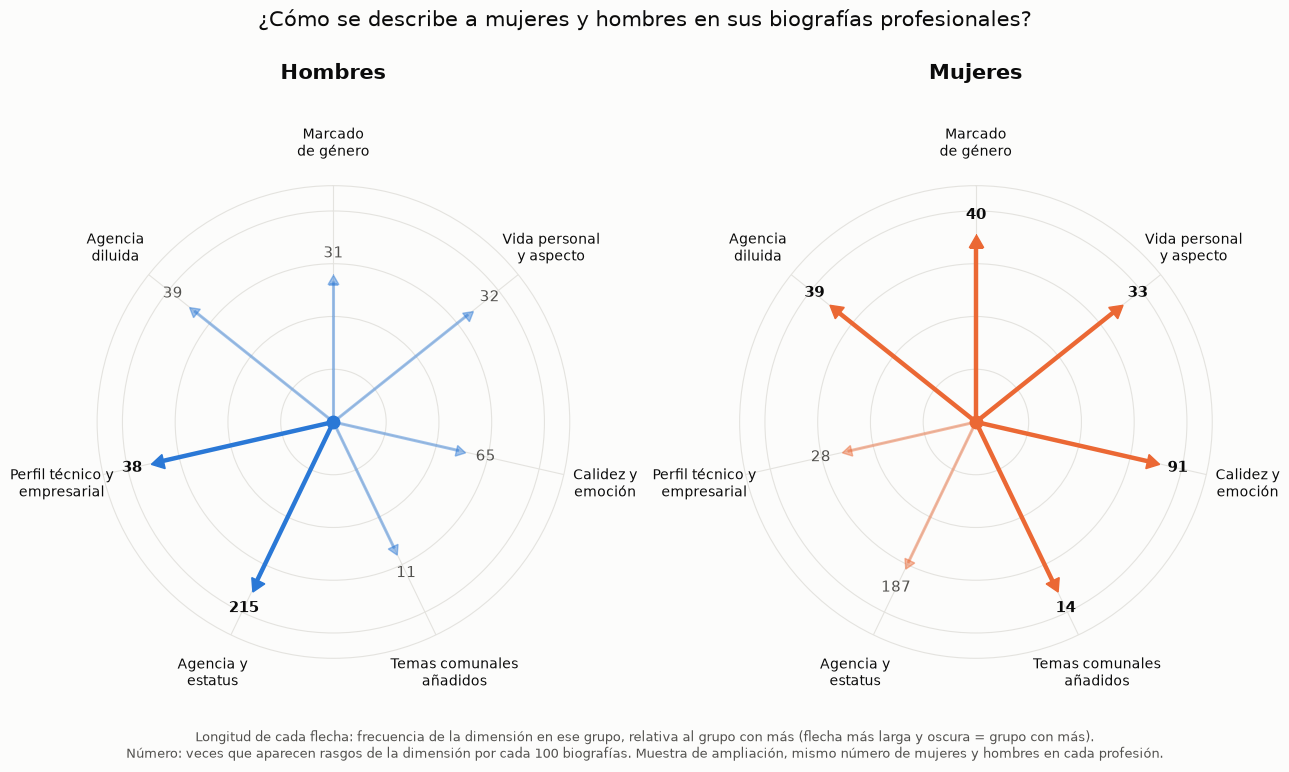

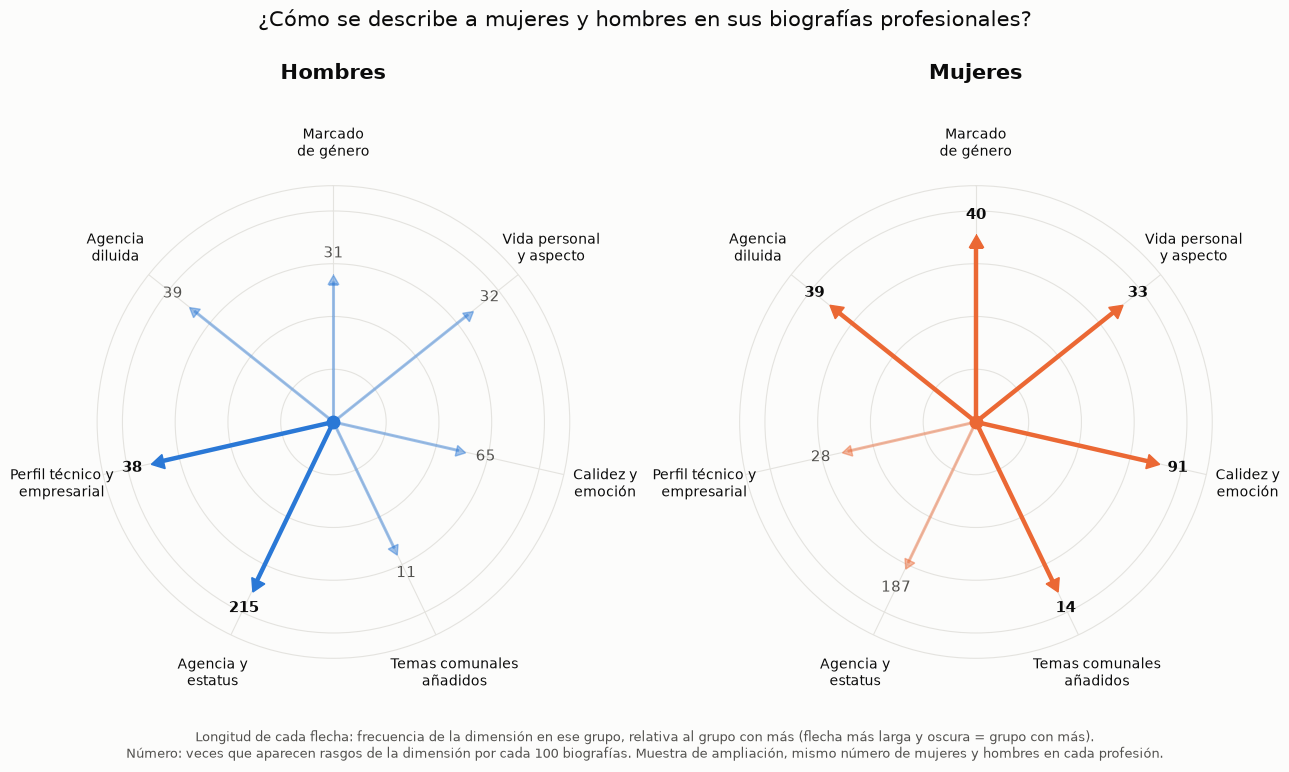

In [15]:
import matplotlib
import matplotlib.pyplot as plt

ETIQUETAS = {"M1": "Marcado\nde género", "M2": "Vida personal\ny aspecto",
             "M3": "Calidez y\nemoción", "M4": "Temas comunales\nañadidos", "M5": "Agencia y\nestatus",
             "M6": "Perfil técnico y\nempresarial", "M7": "Agencia\ndiluida"}
COLOR = {"Hombres": "#2a78d6", "Mujeres": "#eb6834"}
TINTA, TINTA_2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

def tabla_radial(base):
    return pd.DataFrame({"indice": list(DIMENSIONES),
                         "Hombres": [base.loc[base.mujer == 0, d].mean() * 100 for d in DIMENSIONES],
                         "Mujeres": [base.loc[base.mujer == 1, d].mean() * 100 for d in DIMENSIONES]}).fillna(0)

def grafico_radial(tabla, titulo, nota, archivo=None):
    d = tabla.copy()
    maximo = d[["Hombres", "Mujeres"]].max(axis=1).replace(0, 1)
    angulos = np.linspace(0, 2 * np.pi, len(d), endpoint=False)
    fig, ejes = plt.subplots(1, 2, figsize=(13, 7.6), subplot_kw={"projection": "polar"}, facecolor=FONDO)
    for ax, grupo in zip(ejes, ["Hombres", "Mujeres"]):
        ax.set_facecolor(FONDO)
        ax.set_theta_zero_location("N")
        ax.set_theta_direction(-1)
        ax.set_thetalim(0, 2 * np.pi)
        ax.set_ylim(0, 1.12)
        ax.set_yticks([0.25, 0.5, 0.75, 1.0])
        ax.set_yticklabels([])
        ax.set_xticks(angulos)
        ax.set_xticklabels([ETIQUETAS.get(i, i) for i in d["indice"]], color=TINTA, fontsize=10)
        ax.tick_params(axis="x", pad=20)
        ax.grid(color=REJILLA, linewidth=0.8)
        ax.spines["polar"].set_color(REJILLA)
        otro = "Mujeres" if grupo == "Hombres" else "Hombres"
        for ang, valor, valor_otro, mx in zip(angulos, d[grupo], d[otro], maximo):
            r = valor / mx * 0.85
            gana = valor >= valor_otro
            col, lw, alfa = COLOR[grupo], (3.2 if gana else 2.2), (1 if gana else 0.45)
            ax.plot([ang, ang], [0, r], color=col, lw=lw, alpha=alfa, solid_capstyle="butt", zorder=3)
            ax.plot(ang, r, marker=(3, 0, -np.degrees(ang)), markersize=12 if gana else 9,
                    color=col, alpha=alfa, zorder=4)
            ax.text(ang, r + 0.13, f"{valor:.0f}", ha="center", va="center", zorder=5, fontsize=10.5,
                    color=TINTA if gana else TINTA_2, fontweight="bold" if gana else "normal")
        ax.plot(0, 0, "o", color=COLOR[grupo], markersize=9, zorder=5)
        ax.set_title(grupo, color=TINTA, fontsize=15, fontweight="bold", pad=34)
    fig.suptitle(titulo, fontsize=15, color=TINTA, y=0.995)
    fig.text(0.5, 0.01, nota, ha="center", fontsize=9, color=TINTA_2)
    plt.tight_layout(rect=(0, 0.08, 1, 0.95))
    if archivo:
        fig.savefig(archivo, dpi=200, facecolor=FONDO, bbox_inches="tight")
    return fig

NOTA = ("Longitud de cada flecha: frecuencia de la dimensión en ese grupo, relativa al grupo con más (flecha más larga "
        "y oscura = grupo con más).\nNúmero: veces que aparecen rasgos de la dimensión por cada 100 biografías. "
        f"{ETIQUETA_FASE[0].upper() + ETIQUETA_FASE[1:]}, mismo número de mujeres y hombres en cada profesión.")
grafico_radial(tabla_radial(base_dims), "¿Cómo se describe a mujeres y hombres en sus biografías profesionales?",
               NOTA, RESULTADOS / f"grafico_radial_{SUF}.png")
plt.show()

### Un gráfico radial por profesión
Se guardan en `resultados/radiales_por_profesion_confirmacion/`. Cambia `PROFESION_A_VER` para ver una aquí.

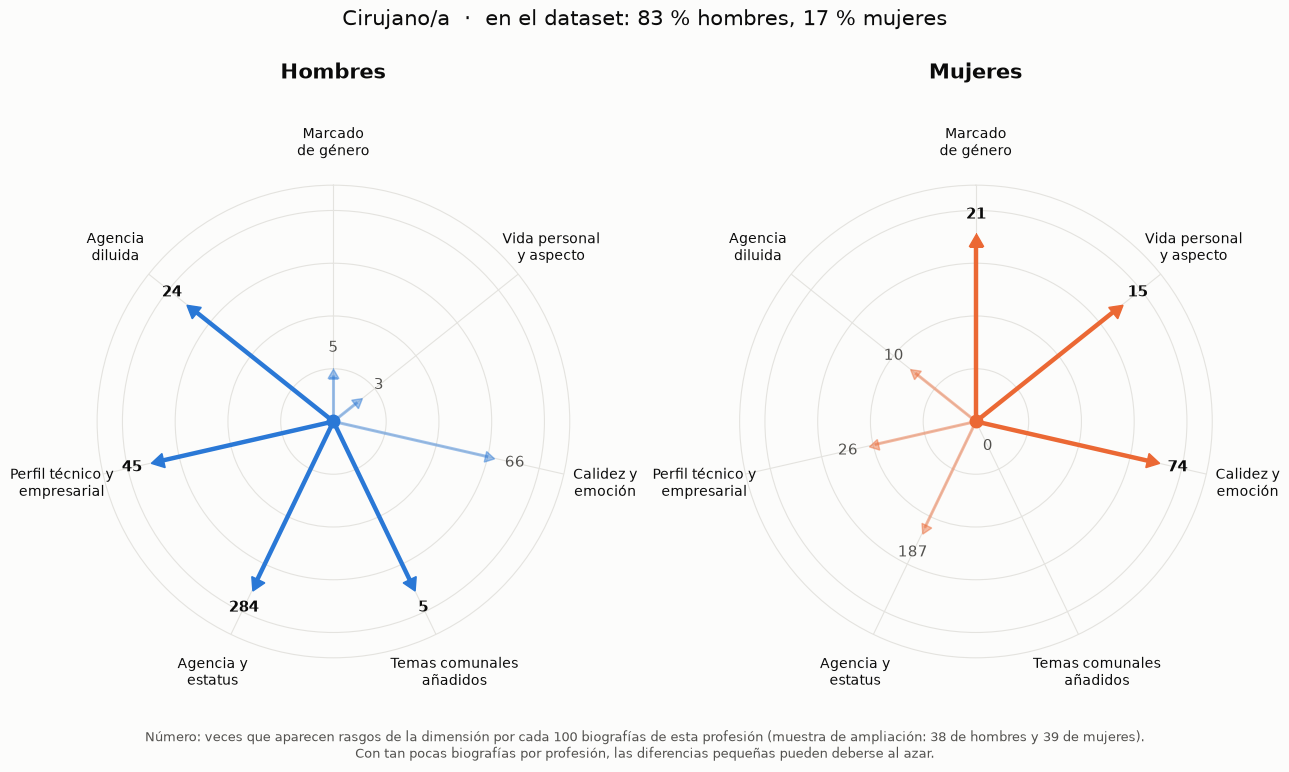

Gráficos guardados en resultados/radiales_por_profesion_ampliacion


In [16]:
def nombre_archivo(texto):
    t = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "_", t.lower()).strip("_")

CARPETA_RADIALES = RESULTADOS / f"radiales_por_profesion_{SUF}"
CARPETA_RADIALES.mkdir(exist_ok=True)
PROFESION_A_VER = "surgeon"

for prof, g in base_dims.groupby("profesion"):
    nombre = NOMBRES.get(prof, prof)
    titulo = (f"{nombre[0].upper() + nombre[1:]}  ·  en el dataset: "
              f"{100 - COMP[prof]:.0f} % hombres, {COMP[prof]:.0f} % mujeres")
    nota = (f"Número: veces que aparecen rasgos de la dimensión por cada 100 biografías de esta profesión "
            f"({ETIQUETA_FASE}: {int((g.mujer == 0).sum())} de hombres y {int((g.mujer == 1).sum())} de mujeres).\n"
            "Con tan pocas biografías por profesión, las diferencias pequeñas pueden deberse al azar.")
    fig = grafico_radial(tabla_radial(g), titulo, nota, CARPETA_RADIALES / f"radial_{nombre_archivo(nombre)}.png")
    if prof == PROFESION_A_VER:
        plt.show()
    else:
        plt.close(fig)
print("Gráficos guardados en", CARPETA_RADIALES)

## 14. Métrica de sesgo de género (0 a 1)
Usa **solo las variables confirmadas** en el confirmatorio y **se ajusta a la profesión** de cada biografía.

**Parte 1 · Sesgo por presencia (70 %).** Rasgos del lado mujeres (marcado de género, vida personal, comunales,
agencia diluida). Cada rasgo pesa según **cuánto más aparece en mujeres que en hombres de esa profesión**: un rasgo
sin brecha en esa profesión no pesa. 0 = no tiene ninguno de los rasgos de sesgo detectados para su profesión;
1 = los tiene todos.

**Parte 2 · Omisión agéntica (30 %).** Rasgos del lado hombres (agencia, estatus, perfil técnico o empresarial puesto
en valor). Cada rasgo pesa según **lo habitual que es en las biografías de hombres de esa profesión** (solo cuenta si
aparece al menos en el `MIN_TASA_HOMBRES` %). 0 = tiene todo lo que suele aparecer en los hombres de su profesión;
1 = le falta todo.

Si en una profesión **ningún** rasgo agéntico confirmado llega al `MIN_TASA_HOMBRES` % en los hombres, la parte 2
vale 0 (no falta nada de lo habitual). Así el total se calcula igual en todas las profesiones.

**Total = 0,70 × parte 1 + 0,30 × parte 2.** 0 sería lo ideal; 1, que cumple todos los sesgos y omite todo lo agéntico.

- Las variables que **no aplican** a una biografía no cuentan (ni suman ni restan).
- Con unas 40 biografías por profesión y género, las tasas de cada profesión son inestables. Por eso se **suavizan**
  hacia las tasas generales: peso de la profesión = n / (n + `K_SUAVIZADO`).
- Si la profesión no está entre las 28, se usan las tasas generales.
- Las tasas de referencia salen de esta misma muestra de confirmación: la comparación entre mujeres y hombres es descriptiva.

In [17]:
TODAS = "(todas)"
VARS_METRICA = CONFIRMADAS if VARIABLES_METRICA == "confirmadas" else VARIABLES_SESGO
print("Variables en la métrica:", len(VARS_METRICA),
      f"({sum(LADO[v] == 'mujeres' for v in VARS_METRICA)} de presencia, "
      f"{sum(LADO[v] == 'hombres' for v in VARS_METRICA)} de omisión)")
if not VARS_METRICA:
    print("⚠ No hay variables confirmadas: la métrica no se puede calcular. "
          "Para explorar, pon VARIABLES_METRICA = 'hipotesis' en la configuración.")

def tabla_tasas(validas, cod, variables):
    """Tasa de cada rasgo en mujeres y hombres, por profesión y en general (sobre las biografías a las que aplica)."""
    filas = []
    base = validas[["profesion", "mujer"]].join(cod[variables])
    for v in variables:
        d = base[["profesion", "mujer", v]].dropna()
        grupos = [(TODAS, d)] + list(d.groupby("profesion"))
        for prof, g in grupos:
            h, m = g.loc[g.mujer == 0, v], g.loc[g.mujer == 1, v]
            filas.append({"variable": v, "profesion": prof, "tasa_h": h.mean() if len(h) else np.nan,
                          "tasa_m": m.mean() if len(m) else np.nan, "n_h": len(h), "n_m": len(m)})
    return pd.DataFrame(filas).set_index(["variable", "profesion"])

def calcular_pesos(tasas, variables, profesion):
    filas = []
    for v in variables:
        g = tasas.loc[(v, TODAS)]
        if profesion is not None and (v, profesion) in tasas.index:
            p = tasas.loc[(v, profesion)]
            n = min(p["n_h"], p["n_m"])
            lam = n / (n + K_SUAVIZADO) if n > 0 else 0.0
            th = p["tasa_h"] if pd.notna(p["tasa_h"]) else g["tasa_h"]
            tm = p["tasa_m"] if pd.notna(p["tasa_m"]) else g["tasa_m"]
        else:
            lam, th, tm = 0.0, g["tasa_h"], g["tasa_m"]
        th_s = lam * th + (1 - lam) * g["tasa_h"]
        tm_s = lam * tm + (1 - lam) * g["tasa_m"]
        if LADO[v] == "mujeres":
            peso = max(0.0, tm_s - th_s)
        else:
            peso = th_s if th_s * 100 >= MIN_TASA_HOMBRES else 0.0
        filas.append({"variable": v, "dimension": DIM_DE[v], "lado": LADO[v], "peso": peso,
                      "tasa_h_ref": th_s, "tasa_m_ref": tm_s, "tasa_h_prof": th, "tasa_m_prof": tm,
                      "tasa_h_gen": g["tasa_h"], "tasa_m_gen": g["tasa_m"], "suavizado_prof": lam})
    return pd.DataFrame(filas).set_index("variable")

def metrica_biografia(codigos, profesion, pesos=None):
    """codigos: Serie 0/1/vacío de una biografía. Devuelve las dos partes, el total y el detalle."""
    pesos = PESOS if pesos is None else pesos
    prof = profesion if profesion in pesos else None
    P = pesos[prof].copy()
    P["x"] = [codigos.get(v, np.nan) for v in P.index]
    partes = {}
    for lado, nombre in [("mujeres", "presencia"), ("hombres", "omision")]:
        q = P[(P["lado"] == lado) & (P["peso"] > 0) & P["x"].notna()]
        suma = q["peso"].sum()
        if suma > 0:
            mal = q["x"] if lado == "mujeres" else 1 - q["x"]
            partes[nombre] = float((q["peso"] * mal).sum() / suma)
        elif lado == "hombres":
            partes[nombre] = 0.0   # en su profesión no hay ningún rasgo agéntico habitual: no falta nada
        else:
            partes[nombre] = np.nan
        P.loc[q.index, "peso_relativo"] = q["peso"] / suma if suma > 0 else np.nan
    disponibles = {k: w for k, w in [("presencia", PESO_PRESENCIA), ("omision", PESO_OMISION)] if pd.notna(partes[k])}
    total_w = sum(disponibles.values())
    total = sum(partes[k] * w for k, w in disponibles.items()) / total_w if total_w > 0 else np.nan
    escala = {k: (w / total_w if total_w > 0 else 0) for k, w in [("presencia", PESO_PRESENCIA), ("omision", PESO_OMISION)]}

    def estado(f):
        if pd.isna(f["x"]):
            return "no aplica"
        if f["peso"] <= 0:
            return "sin peso en esta profesión"
        if f["lado"] == "mujeres":
            return "presente (sesgo)" if f["x"] == 1 else "ausente (bien)"
        return "presente (bien)" if f["x"] == 1 else "falta (omisión)"

    P["estado"] = P.apply(estado, axis=1)
    P["aporta_al_total"] = 0.0
    mp = P["estado"] == "presente (sesgo)"
    mo = P["estado"] == "falta (omisión)"
    P.loc[mp, "aporta_al_total"] = escala["presencia"] * P.loc[mp, "peso_relativo"]
    P.loc[mo, "aporta_al_total"] = escala["omision"] * P.loc[mo, "peso_relativo"]
    return {"profesion": prof, "presencia": partes["presencia"], "omision": partes["omision"], "total": total,
            "detalle": P.reset_index()}

def pct(x):
    return "—" if pd.isna(x) else f"{x * 100:.0f} %"

def explicar(res, mostrar_bien=True):
    prof = res["profesion"]
    nombre_prof = NOMBRES.get(prof, prof) if prof else "todas las profesiones (no hay una equivalente)"
    det = res["detalle"]
    print("=" * 88)
    print("MÉTRICA DE SESGO DE GÉNERO   (0 = ningún sesgo · 1 = todos los sesgos detectados)")
    print("Profesión de referencia:", nombre_prof)
    print("=" * 88)
    print(f"TOTAL: {res['total']:.2f}" if pd.notna(res["total"]) else "TOTAL: no se puede calcular")
    print(f"  · Sesgo por presencia: {res['presencia']:.2f}  (pesa {PESO_PRESENCIA * 100:.0f} %)"
          if pd.notna(res["presencia"]) else "  · Sesgo por presencia: sin rasgos aplicables")
    print(f"  · Omisión agéntica:    {res['omision']:.2f}  (pesa {PESO_OMISION * 100:.0f} %)"
          if pd.notna(res["omision"]) else "  · Omisión agéntica: sin rasgos aplicables")

    def minus(t):
        return t[0].lower() + t[1:]

    def linea(f, simbolo):
        print(f"  {simbolo} {ETIQUETA[f['variable']]}  [{f['dimension']}]   +{f['aporta_al_total']:.2f} al total")
        print(f"      referencia {'para esta profesión' if prof else 'general'}: mujeres {pct(f['tasa_m_ref'])}, "
              f"hombres {pct(f['tasa_h_ref'])}")

    def lista(q, simbolo):
        grandes = q[q["aporta_al_total"] >= 0.005]
        for _, f in grandes.iterrows():
            linea(f, simbolo)
        if len(q) > len(grandes):
            print(f"  (y {len(q) - len(grandes)} más con un peso casi nulo en esta profesión: "
                  + "; ".join(minus(ETIQUETA[v]) for v in q.loc[~q.index.isin(grandes.index), "variable"]) + ")")

    print("\nPARTE 1 · SESGO POR PRESENCIA — rasgos que suben la puntuación")
    q = det[det["estado"] == "presente (sesgo)"].sort_values("aporta_al_total", ascending=False)
    if q.empty:
        print("  ✓ Ninguno.")
    lista(q, "✗")
    if mostrar_bien:
        q = det[(det["lado"] == "mujeres") & (det["estado"] == "ausente (bien)")]
        if not q.empty:
            print("  No aparecen (bien):", "; ".join(minus(ETIQUETA[v]) for v in q["variable"]))

    print("\nPARTE 2 · OMISIÓN AGÉNTICA — lo que suele aparecer en los hombres de su profesión y falta")
    q = det[det["estado"] == "falta (omisión)"].sort_values("aporta_al_total", ascending=False)
    if q.empty:
        print("  ✓ No falta nada relevante.")
    lista(q, "○")
    if mostrar_bien:
        q = det[(det["lado"] == "hombres") & (det["estado"] == "presente (bien)")]
        if not q.empty:
            print("  Sí aparecen (bien):", "; ".join(minus(ETIQUETA[v]) for v in q["variable"]))
    na = det[det["estado"] == "no aplica"]
    if not na.empty:
        print("\nNo aplican a este texto:", "; ".join(minus(ETIQUETA[v]) for v in na["variable"]))
    print("\nSon señales, no un veredicto: un rasgo no es incorrecto en sí mismo; el sesgo es que se use")
    print("sistemáticamente más con un género que con otro.")

if VARS_METRICA:
    TASAS = tabla_tasas(validas_r, cod_r, VARS_METRICA)
    PESOS = {p: calcular_pesos(TASAS, VARS_METRICA, p) for p in validas_r["profesion"].unique()}
    PESOS[None] = calcular_pesos(TASAS, VARS_METRICA, None)
    pd.concat({str(k): v for k, v in PESOS.items()}, names=["profesion"]).to_csv(RESULTADOS / "pesos_metrica.csv")
    print("Pesos generales (sin ajustar a profesión):")
    display(PESOS[None][["dimension", "lado", "peso", "tasa_h_gen", "tasa_m_gen"]].round(3))

Variables en la métrica: 17 (11 de presencia, 6 de omisión)
Pesos generales (sin ajustar a profesión):


,dimension,lado,peso,tasa_h_gen,tasa_m_gen
variable,,,,,
marcado_genero,M1,mujeres,0.027,0.008,0.035
marca_genero_persona,M1,mujeres,0.025,0.007,0.032
forma_nombrar,M1,mujeres,0.060,0.527,0.587
menciona_hijos,M2,mujeres,0.023,0.030,0.053
orientacion_cuidado,M3,mujeres,0.067,0.180,0.247
n_adj_calidez,M3,mujeres,0.028,0.068,0.096
n_terminos_emocion,M3,mujeres,0.067,0.223,0.289
pasion_emocion,M3,mujeres,0.089,0.184,0.273
bienestar_sanacion_ctx,M3,mujeres,0.011,0.002,0.013


### Métrica de todas las biografías de la muestra de confirmación
Media de mujeres y hombres, diferencia ajustada por profesión, *d* de Cohen y si la brecha cambia según el
% de mujeres de la profesión.

**Validación cruzada:** si cada biografía se puntuara con pesos calculados con ella misma, la métrica exageraría la
diferencia (los pesos se ajustarían al azar de la muestra). Por eso la muestra se divide en `N_PLIEGUES` partes y cada
biografía se puntúa con pesos calculados con las demás. Aun así, la lista de variables confirmadas sale de esta misma
ronda: para una evaluación totalmente independiente, la métrica se aplica después a biografías nuevas (detector).

In [18]:
def pesos_desde(validas, cod):
    tasas = tabla_tasas(validas, cod, VARS_METRICA)
    pesos = {p: calcular_pesos(tasas, VARS_METRICA, p) for p in validas["profesion"].unique()}
    pesos[None] = calcular_pesos(tasas, VARS_METRICA, None)
    return pesos

if VARS_METRICA:
    # Validación cruzada: cada biografía se puntúa con pesos calculados SIN su parte de la muestra
    orden = validas_r.sample(frac=1, random_state=0).index
    pliegue = pd.Series(validas_r.loc[orden].groupby(["profesion", "genero"]).cumcount().values % N_PLIEGUES,
                        index=orden).reindex(validas_r.index)
    res_r = [None] * len(validas_r)
    for k in range(N_PLIEGUES):
        entreno = pliegue != k
        pesos_k = pesos_desde(validas_r[entreno], cod_r[entreno])
        for pos, i in enumerate(validas_r.index):
            if pliegue[i] == k:
                res_r[pos] = metrica_biografia(cod_r.loc[i], validas_r.at[i, "profesion"], pesos_k)
    met_r = validas_r[["idx", "profesion", "genero", "mujer", "tipo_prof"]].copy()
    met_r["presencia"] = [r["presencia"] for r in res_r]
    met_r["omision"] = [r["omision"] for r in res_r]
    met_r["total"] = [r["total"] for r in res_r]
    met_r.to_csv(RESULTADOS / f"metrica_{SUF}.csv", index=False)

    filas = []
    for col, nombre in [("total", "Total"), ("presencia", "Parte 1 · presencia"), ("omision", "Parte 2 · omisión")]:
        d = met_r.dropna(subset=[col])
        mod = smf.ols(f"{col} ~ mujer + C(profesion)", d).fit()
        li, ls = mod.conf_int().loc["mujer"]
        filas.append({"metrica": nombre, "media_hombres": d.loc[d.mujer == 0, col].mean(),
                      "media_mujeres": d.loc[d.mujer == 1, col].mean(), "diferencia_ajustada": mod.params["mujer"],
                      "IC95_inf": li, "IC95_sup": ls, "p": mod.pvalues["mujer"],
                      "d_cohen": d_cohen(d.loc[d.mujer == 0, col], d.loc[d.mujer == 1, col]),
                      "p_tipo_profesion": interaccion_tipo(d, col)})
    resumen_met = pd.DataFrame(filas)
    resumen_met.to_csv(RESULTADOS / f"metrica_resumen_{SUF}.csv", index=False)
    display(resumen_met.round(4))

    por_prof = (met_r.groupby(["profesion", "genero"])["total"].mean().unstack().round(3)
                .rename(columns={"man": "hombres", "woman": "mujeres"}))
    por_prof["brecha (M − H)"] = (por_prof["mujeres"] - por_prof["hombres"]).round(3)
    por_prof.insert(0, "% mujeres en el dataset", COMP.reindex(por_prof.index).round(1))
    por_prof.index = [NOMBRES.get(p, p) for p in por_prof.index]
    por_prof = por_prof.sort_values("brecha (M − H)", ascending=False)
    por_prof.to_csv(RESULTADOS / f"metrica_por_profesion_{SUF}.csv")
    display(por_prof)
    print(met_r.groupby(["tipo_prof", "genero"])["total"].mean().unstack().round(3))

,metrica,media_hombres,media_mujeres,diferencia_ajustada,IC95_inf,IC95_sup,p,d_cohen,p_tipo_profesion
0,Total,0.3171,0.3694,0.0506,0.0360,0.0653,0.0,0.2902,0.2686
1,Parte 1 · presencia,0.1611,0.2118,0.0493,0.0304,0.0681,0.0,0.2189,0.2447
2,Parte 2 · omisión,0.6811,0.7370,0.0539,0.0303,0.0775,0.0,0.1931,0.3344


genero,% mujeres en el dataset,hombres,mujeres,brecha (M − H)
interiorista,80.8,0.304,0.494,0.190
DJ,14.2,0.308,0.435,0.127
pastor/a,24.0,0.345,0.467,0.122
dietista,92.7,0.399,0.517,0.118
rapero/a,9.7,0.263,0.377,0.114
compositor/a,16.4,0.226,0.323,0.097
fotógrafo/a,35.7,0.367,0.462,0.095
psicólogo/a,63.4,0.324,0.400,0.076
profesor/a de yoga,84.5,0.398,0.469,0.071
profesor/a universitario/a,45.1,0.226,0.295,0.069


genero                        man  woman
tipo_prof                               
entre 35 y 65 % de mujeres  0.317  0.355
menos del 35 % de mujeres   0.286  0.350
más del 65 % de mujeres     0.372  0.429


### Gráfico de la métrica por profesión
Media de la métrica total de mujeres y hombres en cada profesión, ordenadas por la brecha.

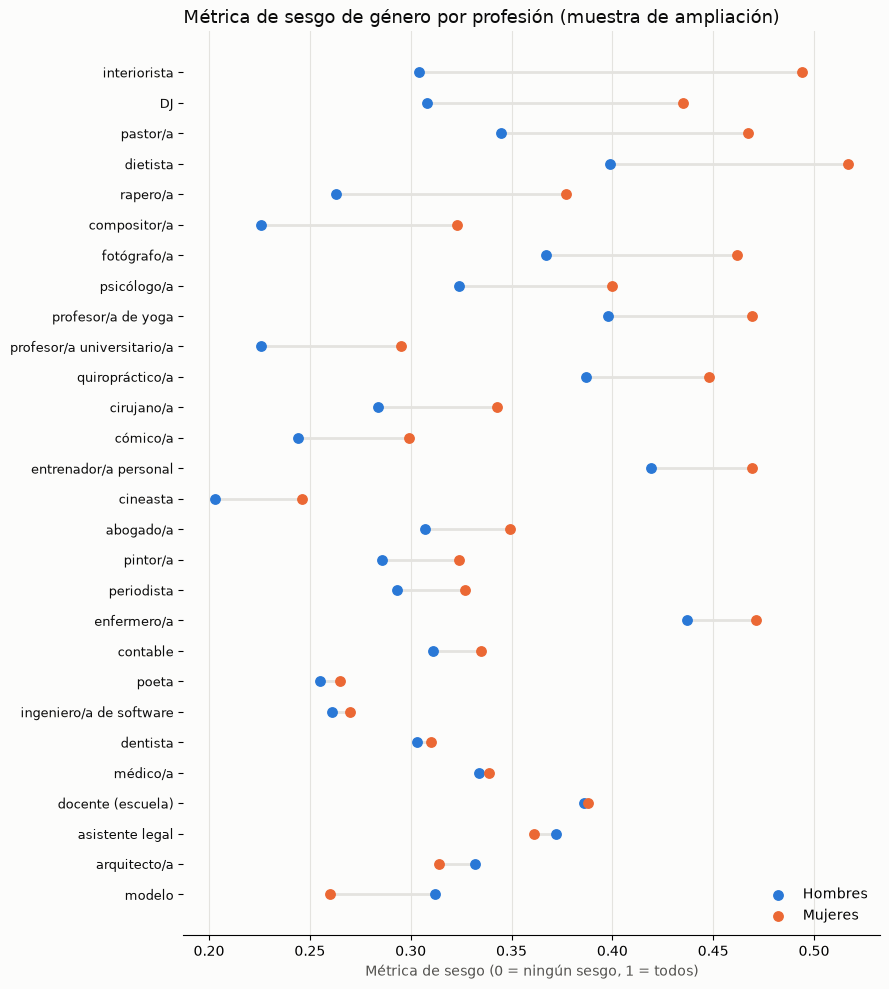

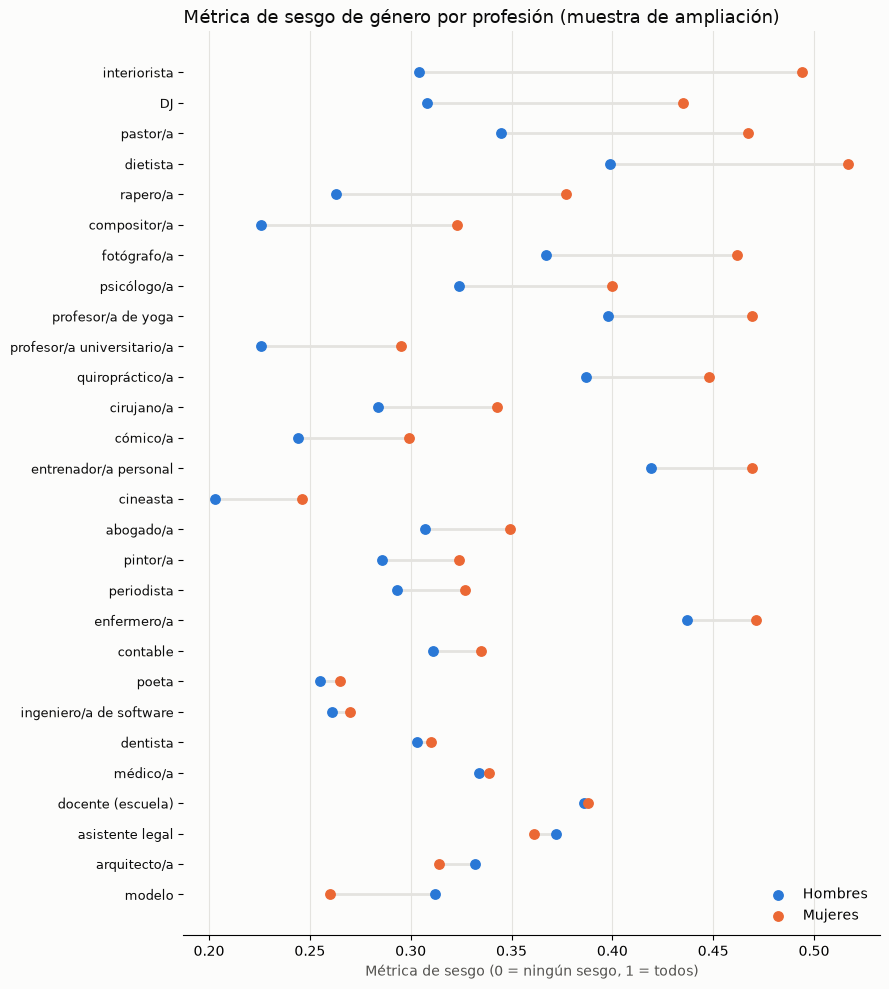

In [19]:
if VARS_METRICA:
    pp = por_prof.sort_values("brecha (M − H)")
    fig, ax = plt.subplots(figsize=(9, 10), facecolor=FONDO)
    ax.set_facecolor(FONDO)
    y = np.arange(len(pp))
    ax.hlines(y, pp[["hombres", "mujeres"]].min(axis=1), pp[["hombres", "mujeres"]].max(axis=1),
              color=REJILLA, lw=2, zorder=1)
    ax.scatter(pp["hombres"], y, color=COLOR["Hombres"], s=46, label="Hombres", zorder=2)
    ax.scatter(pp["mujeres"], y, color=COLOR["Mujeres"], s=46, label="Mujeres", zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels(pp.index, color=TINTA, fontsize=9.5)
    ax.set_xlabel("Métrica de sesgo (0 = ningún sesgo, 1 = todos)", color=TINTA_2)
    ax.grid(axis="x", color=REJILLA, lw=0.8)
    for s in ["top", "right", "left"]:
        ax.spines[s].set_visible(False)
    ax.legend(frameon=False, loc="lower right")
    ax.set_title(f"Métrica de sesgo de género por profesión ({ETIQUETA_FASE})", color=TINTA, fontsize=13, loc="left")
    plt.tight_layout()
    fig.savefig(RESULTADOS / f"metrica_por_profesion_{SUF}.png", dpi=200, facecolor=FONDO)
    plt.show()

## 15. Ejemplo: una biografía al azar, con su explicación
Elige una biografía de la muestra de confirmación (usa su anotación, no hace llamadas) y muestra la métrica desglosada y por qué
vale lo que vale. Vuelve a ejecutar para ver otra; para repetir una, pon su número en `SEMILLA`.

In [20]:
SEMILLA = None
SOLO_MUJERES = True

if VARS_METRICA:
    candidatas = validas_r[validas_r["genero"] == "woman"] if SOLO_MUJERES else validas_r
    semilla = SEMILLA if SEMILLA is not None else int(np.random.default_rng().integers(1_000_000))
    i = candidatas.sample(1, random_state=semilla).index[0]
    print(f"SEMILLA = {semilla} · profesión: {NOMBRES.get(validas_r.at[i, 'profesion'])} · "
          f"género: {'mujer' if validas_r.at[i, 'mujer'] else 'hombre'}\n")
    print(validas_r.at[i, "texto"], "\n")
    ejemplo = metrica_biografia(cod_r.loc[i], validas_r.at[i, "profesion"])
    explicar(ejemplo)

SEMILLA = 147302 · profesión: asistente legal · género: mujer

Before joining McDermott Will & Emery, Alyse was a Senior Litigation Paralegal at Frommer Lawrence & Haug in New York. Alyse is passionate about giving back and volunteers her time to help those in need as often as she can. 

MÉTRICA DE SESGO DE GÉNERO   (0 = ningún sesgo · 1 = todos los sesgos detectados)
Profesión de referencia: asistente legal
TOTAL: 0.69
  · Sesgo por presencia: 0.56  (pesa 70 %)
  · Omisión agéntica:    1.00  (pesa 30 %)

PARTE 1 · SESGO POR PRESENCIA — rasgos que suben la puntuación
  ✗ La motivación se cuenta como emoción o pasión  [M3]   +0.14 al total
      referencia para esta profesión: mujeres 20 %, hombres 16 %
  ✗ Se la nombra por el nombre de pila  [M1]   +0.12 al total
      referencia para esta profesión: mujeres 62 %, hombres 59 %
  ✗ Se pone el foco en cuidar o ayudar a otros  [M3]   +0.10 al total
      referencia para esta profesión: mujeres 18 %, hombres 15 %
  ✗ Palabras de activismo 

### Analizar un texto nuevo
Anota el texto con el modelo (3 llamadas) y le aplica la métrica. La profesión es opcional (en inglés o castellano);
si no está entre las 28, se usan las tasas generales.

In [21]:
def profesion_codigo(profesion):
    if not profesion:
        return None
    p = profesion.strip().lower()
    for en in PROFESIONES:
        if p in (en, en.replace("_", " "), NOMBRES.get(en, "").lower()):
            return en
    return None

def analizar_texto(texto, profesion=None):
    if not VARS_METRICA:
        print("No hay variables en la métrica (ninguna confirmada): no se puede analizar.")
        return None
    fila = anotar(texto, enmascarar_lote([texto])[0])
    codigos = codificar(pd.DataFrame([fila])).iloc[0]
    res = metrica_biografia(codigos, profesion_codigo(profesion))
    explicar(res)
    return res

texto = """She is a passionate pediatric nurse who loves helping families. As a woman in healthcare,
Maria volunteers at a women's network and enjoys baking with her two children."""
# resultado = analizar_texto(texto, profesion="enfermera")   # quita el # para probarlo

## 16. Variables utilizadas y cómo se agrupan
Tabla de todas las variables anotadas: en qué llamada se preguntan, su tipo, para qué se usan (sesgo, descriptiva o
control), su dimensión y lado, qué ha cambiado respecto a la versión original y si se confirmó. Se guarda en
`resultados/variables_utilizadas.csv` y la agrupación en `resultados/agrupacion_variables.csv`.

Vamos a guardar los resultados:

In [23]:
import zipfile
from pathlib import Path

fase = FASE   # "ampliacion"
archivos = [p for p in Path("resultados").rglob("*") if p.is_file() and fase in str(p)]
archivos += [Path(f"anotaciones_{fase}.csv"), Path(f"cache/muestra_{fase}.parquet"),
             Path("sesgo_genero_parte_2.ipynb")]

nombre_zip = f"salidas_parte_2_{fase}.zip"
with zipfile.ZipFile(nombre_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for p in archivos:
        if p.exists():
            z.write(p)
            print("añadido:", p)
        else:
            print("no existe:", p)
print("\nCreado:", nombre_zip)

añadido: resultados/pruebas_por_profesion_ampliacion.csv
añadido: resultados/descriptivas_ampliacion.csv
añadido: resultados/metrica_ampliacion.csv
añadido: resultados/grafico_radial_ampliacion.png
añadido: resultados/metrica_por_profesion_ampliacion.png
añadido: resultados/dimensiones_ampliacion.csv
añadido: resultados/brecha_por_tipo_profesion_ampliacion.csv
añadido: resultados/metrica_resumen_ampliacion.csv
añadido: resultados/metrica_por_profesion_ampliacion.csv
añadido: resultados/confirmatorio_ampliacion.csv
añadido: resultados/diferencias_por_profesion_ampliacion.csv
añadido: resultados/radiales_por_profesion_ampliacion/radial_medico_a.png
añadido: resultados/radiales_por_profesion_ampliacion/radial_profesor_a_de_yoga.png
añadido: resultados/radiales_por_profesion_ampliacion/radial_dj.png
añadido: resultados/radiales_por_profesion_ampliacion/radial_rapero_a.png
añadido: resultados/radiales_por_profesion_ampliacion/radial_fotografo_a.png
añadido: resultados/radiales_por_profesion

In [22]:
CAMBIO = {"marcado_genero": "pregunta corregida (sin cargos con género)", "excepcionalidad": "cambia a M1 (más en mujeres)",
          "menciona_voluntariado": "entra en M4", "papel_pareja": "entra en M7",
          "atribuye_logros_a_otros": "entra en M7", "logros_en_pasiva": "entra en M7",
          "n_verbos_rol_apoyo": "entra en M7", "n_expresiones_duda": "entra en M7",
          "espacio_un_genero": "pasa a descriptiva", "titulo_con_genero": "pasa a descriptiva",
          "n_palabras_esfuerzo": "descriptiva (esfuerzo frente a talento)",
          "n_palabras_capacidad": "descriptiva (esfuerzo frente a talento)"}
for v in TIPOS:
    if v.endswith("_ctx"):
        CAMBIO.setdefault(v, "nueva (sustituye a la versión sí / no)")

llamada = {**{v: "forma" for v in VARIABLES_FORMA}, **{v: "contexto" for v in VARIABLES_CONTEXTO},
           **{v: "nombre" for v in VARIABLES_NOMBRE}}
confirmada = dict(zip(conf_r["variable"], conf_r["confirmada"]))
filas = []
for v, t in TIPOS.items():
    if v in DIM_DE:
        uso = "sesgo"
    elif v == "tipo_texto":
        uso = "control"
    else:
        uso = "descriptiva"
    filas.append({"variable": v, "llamada": llamada[v],
                  "tipo": t if isinstance(t, str) else " / ".join(t),
                  "uso": uso, "dimension": DIM_DE.get(v, ""),
                  "nombre_dimension": DIMENSIONES[DIM_DE[v]][0] if v in DIM_DE else "",
                  "lado": LADO.get(v, ""), "cuenta_como_sesgo_si": ETIQUETA.get(v, ""),
                  "cambio": CAMBIO.get(v, "igual"), "confirmada": confirmada.get(v, "")})
variables_usadas = pd.DataFrame(filas).sort_values(["uso", "dimension", "variable"])
variables_usadas.to_csv(RESULTADOS / "variables_utilizadas.csv", index=False)
display(variables_usadas)

agrupacion = pd.DataFrame([{"dimension": d, "nombre": n, "lado": lado,
                            "parte_de_la_metrica": "1 · presencia (70 %)" if lado == "mujeres" else "2 · omisión (30 %)",
                            "n_variables": len(vs), "variables": ", ".join(vs),
                            "confirmadas": ", ".join(v for v in vs if confirmada.get(v) is True)}
                           for d, (n, lado, vs) in DIMENSIONES.items()])
agrupacion.to_csv(RESULTADOS / "agrupacion_variables.csv", index=False)
display(agrupacion)
print("Eliminadas: militar_riesgo, deporte_fisico, aficiones_aire_libre_mecanica, narrativa_expresion, identidad_lgtbi, "
      "obstaculos_genero, menciona_edad, n_frases_vida_personal.")

,variable,llamada,tipo,uso,dimension,nombre_dimension,lado,cuenta_como_sesgo_si,cambio,confirmada
0,tipo_texto,forma,biografia / no_biografia,control,,,,,igual,
25,espacio_un_genero,forma,bool,descriptiva,,,,,pasa a descriptiva,
18,menciona_docencia_mentoria,forma,bool,descriptiva,,,,,igual,
20,menciona_especializacion,forma,bool,descriptiva,,,,,igual,
11,menciona_experiencia,forma,bool,descriptiva,,,,,igual,
10,n_credenciales,forma,int,descriptiva,,,,,igual,
28,n_palabras_capacidad,forma,int,descriptiva,,,,,descriptiva (esfuerzo frente a talento),
29,n_palabras_esfuerzo,forma,int,descriptiva,,,,,descriptiva (esfuerzo frente a talento),
8,posicion_mencion_familiar,forma,primera_mitad / segunda_mitad / no_aparece,descriptiva,,,,,igual,
24,titulo_con_genero,forma,bool,descriptiva,,,,,pasa a descriptiva,


,dimension,nombre,lado,parte_de_la_metrica,n_variables,variables,confirmadas
0,M1,Marcado de género,mujeres,1 · presencia (70 %),3,"marcado_genero, marca_genero_persona, forma_nombrar","marcado_genero, marca_genero_persona, forma_nombrar"
1,M2,Vida personal y aspecto,mujeres,1 · presencia (70 %),7,"menciona_pareja, menciona_hijos, menciona_estado_civil, menciona_padres_origen, presentada_por_otra_persona, mencion...",menciona_hijos
2,M3,Calidez y emoción,mujeres,1 · presencia (70 %),5,"orientacion_cuidado, n_adj_calidez, n_terminos_emocion, pasion_emocion, bienestar_sanacion_ctx","orientacion_cuidado, n_adj_calidez, n_terminos_emocion, pasion_emocion, bienestar_sanacion_ctx"
3,M4,Temas comunales añadidos,mujeres,1 · presencia (70 %),5,"infancia_familias_ctx, estetica_belleza_ctx, activismo_justicia_social_ctx, aficiones_hogar_creativas, menciona_volu...","activismo_justicia_social_ctx, aficiones_hogar_creativas"
4,M5,Agencia y estatus,hombres,2 · omisión (30 %),10,"n_adj_agencia, n_logros, menciona_liderazgo, menciona_impacto, menciona_innovacion, fama_prestigio, valentia_audacia...","n_adj_agencia, n_logros, menciona_liderazgo, fama_prestigio"
5,M6,Perfil técnico y empresarial puesto en valor,hombres,2 · omisión (30 %),3,"ciencia_cuantitativa_ctx, tecnologia_sistemas_ctx, empresa_negocio_ctx","ciencia_cuantitativa_ctx, tecnologia_sistemas_ctx"
6,M7,Agencia diluida,mujeres,1 · presencia (70 %),5,"atribuye_logros_a_otros, logros_en_pasiva, n_verbos_rol_apoyo, n_expresiones_duda, papel_pareja",


Eliminadas: militar_riesgo, deporte_fisico, aficiones_aire_libre_mecanica, narrativa_expresion, identidad_lgtbi, obstaculos_genero, menciona_edad, n_frases_vida_personal.
